# I - Comprehension des données


# 1- Chargement de bibliotheques et du dataset

In [1]:
# importation des bibliotheques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# chargement du dataset
df= pd.read_csv('dbcredit.csv')
df.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


# 2 - Informations du Dataset et connaissance

In [3]:
# dimension du dataset

df.shape

(614, 13)

# 2 - PRE_ANALYSE ET NETTOYAGE DU DATASET

In [4]:
# Description du dataset 

df.describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


In [5]:
# variables manquantes

missing = df.isna().sum() / len(df) *100
missing

Loan_ID              0.000000
Gender               2.117264
Married              0.488599
Dependents           2.442997
Education            0.000000
Self_Employed        5.211726
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           3.583062
Loan_Amount_Term     2.280130
Credit_History       8.143322
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64

In [7]:
# affichage de toutes les colonnes 

pd.set_option("display.max_columns", 13)

In [8]:
# renommer les noms des variables 
df.rename({
    'Gender': 'genre',
    'Married' : 'marrie',
    'Dependents' :'pers_en_charge',
    'Self_Employed':'travailleur_indep',
    'ApplicantIncome':'revenu_demandeur',
    'CoapplicantIncome': 'revenu_codemmandeur',
    'LoanAmount' : 'montant_pret', 
    'Loan_Amount_Term': 'duree_pret',
    'Credit_History' : 'credit_historique',
    'Property_Area':'zone_residence',
    'Loan_Status' : 'statut_pret'
}, axis=1,  inplace =True)

In [9]:
# Supprimer la colonne ID dans le dataset

df.drop('Loan_ID', axis=1, inplace=True)

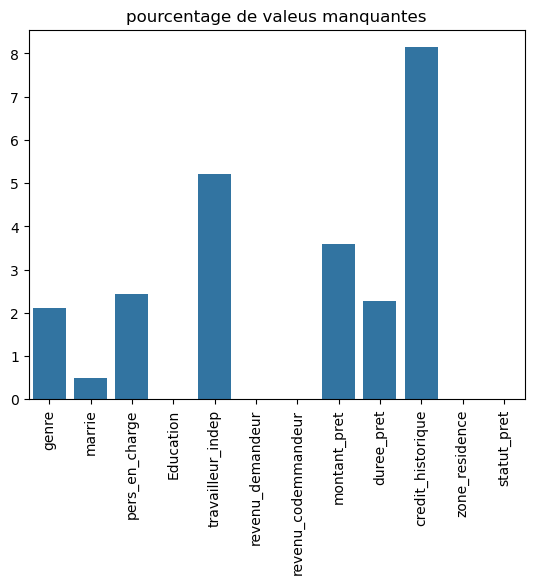

In [10]:
# Visualisation du diagramme en bar des valeurs manquantes(VM)

miss = df.isna().sum() / len(df) *100
sns.barplot(miss)
plt.title('pourcentage de valeus manquantes')
plt.xticks(rotation = 90)
plt.show()

In [11]:
# Verification si les valeurs manquantes pour les VARIABLES QUALITATIVES ont ete corrigées

var_cat_miss = ['genre', 'marrie', 'pers_en_charge', 'credit_historique', 'travailleur_indep']

for col in var_cat_miss:
    df[col] = df[col].fillna(df[col].mode()[0])

df[var_cat_miss].isna().sum()

genre                0
marrie               0
pers_en_charge       0
credit_historique    0
travailleur_indep    0
dtype: int64

In [12]:
# Correction et Verification des valeurs manquantes corrigees pour les VARIABLES QUANTITATIVES 

var_num_miss = ['montant_pret', 'duree_pret']
for col in var_num_miss:
    df[col] = df[col].fillna(df[col].median())

df[var_num_miss].isna().sum()/len(df)*100

montant_pret    0.0
duree_pret      0.0
dtype: float64

In [13]:
# Observation du type de variables pour replacer les modalites confomement a leur variable

df.dtypes

genre                      str
marrie                     str
pers_en_charge             str
Education                  str
travailleur_indep          str
revenu_demandeur         int64
revenu_codemmandeur    float64
montant_pret           float64
duree_pret             float64
credit_historique      float64
zone_residence             str
statut_pret                str
dtype: object

# Problème identifié : 
ci dessous les modalités ne sont pas conformes. Donc il faudra les replacer.

'credit_historique' (float)  ---> en str()

'pers_en_charge' (str) : ----> en int()

In [14]:
# Replace des modalites : 

df['credit_historique'] = df['credit_historique'].replace({
    '0.0' : 'non',
    '1.0' : 'oui'
} ).astype(str)

df.credit_historique.unique()

<StringArray>
['1.0', '0.0']
Length: 2, dtype: str

In [15]:
# Observation des modalites de la variable et de leur type de la variable : pers_en_charge

df['pers_en_charge'].unique()

<StringArray>
['0', '1', '2', '3+']
Length: 4, dtype: str

In [16]:
# Replacement des modalites de la variable : pers_en_charge

df['pers_en_charge'] = df['pers_en_charge'].replace({
    '0' : 0,
    '1' : 1,
    '2': 2,
    '3+' : 3
}).astype(int)

df.pers_en_charge.unique()

array([0, 1, 2, 3])

In [17]:
# Noms des colonnes pour cibler les variables dans le dataset, les vqriqbles categorielles et les variables quantitatives

name_col_cat = ['genre', 'marrie', 'Education','travailleur_indep', 'zone_residence', 'credit_historique']
name_col_num = ['pers_en_charge', 'revenu_demandeur', 'revenu_codemmandeur', 'montant_pret', 'duree_pret']

# 3- Observation des VALEURS EXTREMES et traitement

In [18]:
# Copie du dataset
df1 = df.copy()

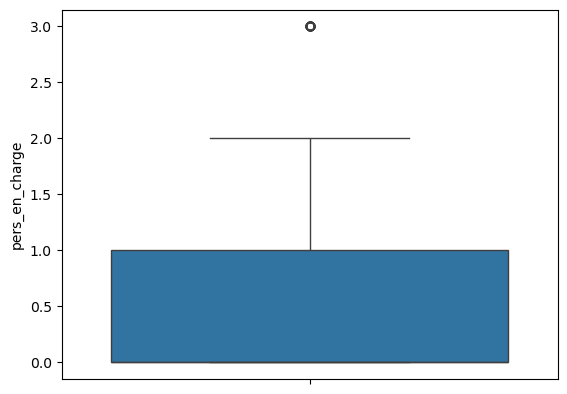

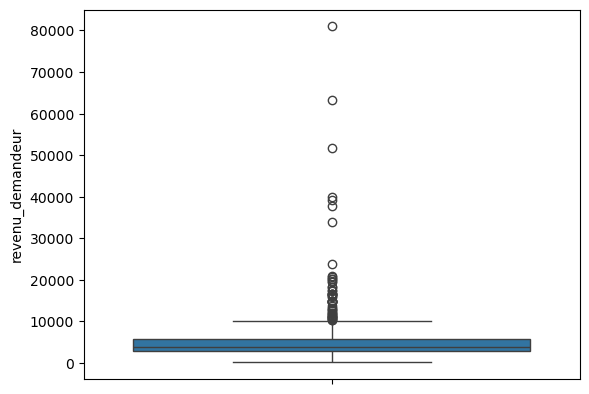

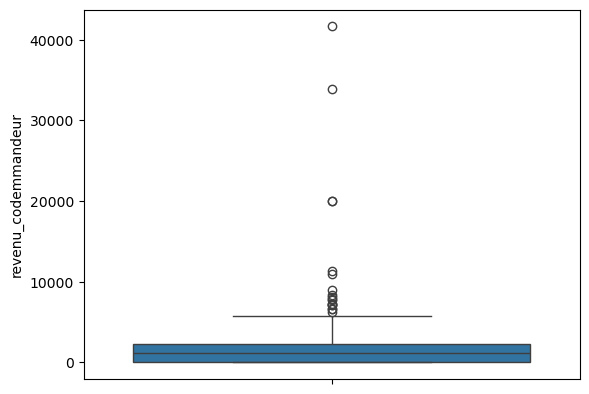

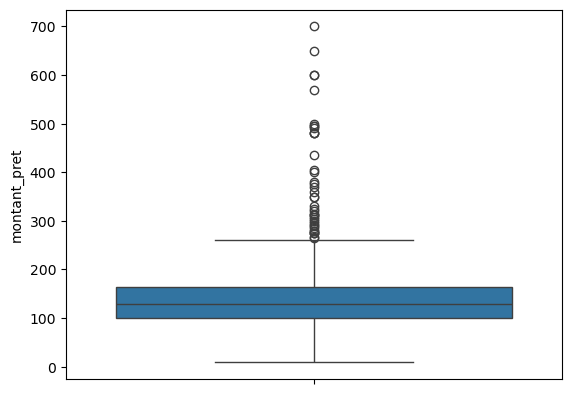

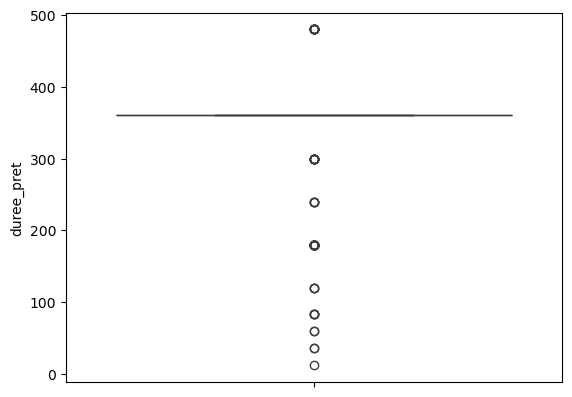

In [19]:
#  Observqtion des valeurs extremes par Box_plot

for col in name_col_num:
    sns.boxplot(df[col])
    plt.xticks(rotation=90)
    plt.show()

In [20]:
# Division du dataset en dataset numeriques et en dataset categorielles

df_num = df[name_col_num]
df_cat = df[name_col_cat]

In [21]:
# Comptage du nombre de valeurs extremes selon les percentiles

for col in name_col_num:
    a = df_num[[col]] < df_num[col].quantile(0.1) 
    b = df_num[[col]] > df_num[col].quantile(0.99)
    print(f"\nvaleurs inferieures: {a.value_counts()}")
    print(f"valeurs superieures: {b.value_counts()}")


valeurs inferieures: pers_en_charge
False             614
Name: count, dtype: int64
valeurs superieures: pers_en_charge
False             614
Name: count, dtype: int64

valeurs inferieures: revenu_demandeur
False               552
True                 62
Name: count, dtype: int64
valeurs superieures: revenu_demandeur
False               607
True                  7
Name: count, dtype: int64

valeurs inferieures: revenu_codemmandeur
False                  614
Name: count, dtype: int64
valeurs superieures: revenu_codemmandeur
False                  607
True                     7
Name: count, dtype: int64

valeurs inferieures: montant_pret
False           552
True             62
Name: count, dtype: int64
valeurs superieures: montant_pret
False           607
True              7
Name: count, dtype: int64

valeurs inferieures: duree_pret
False         554
True           60
Name: count, dtype: int64
valeurs superieures: duree_pret
False         614
Name: count, dtype: int64


les valeurs extremes:

ce valeurs extremes sont de valeurs atypiques. Donc, nous decidons de ne faire aucun traitement.

# 3- ETUDE EXPLORATOIRE

# a-/ 1er niveau: etude de variable univarie
Observation des distributions des variables quantitatifs ou numeriques 

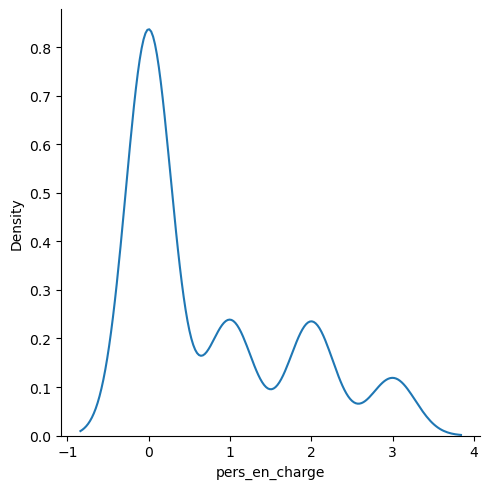

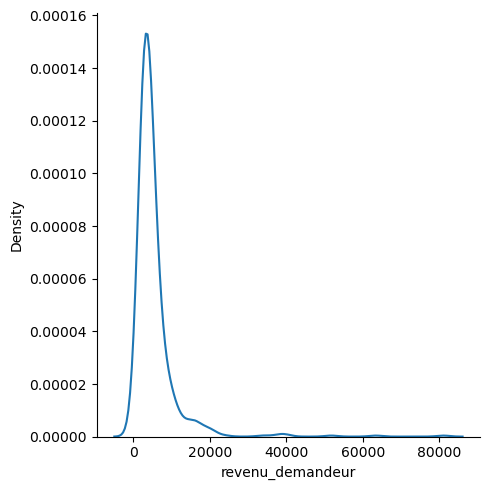

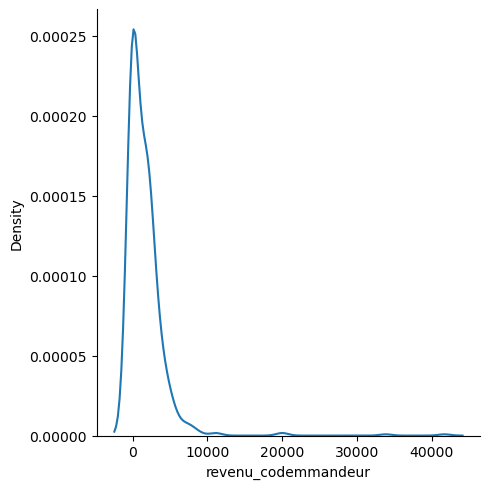

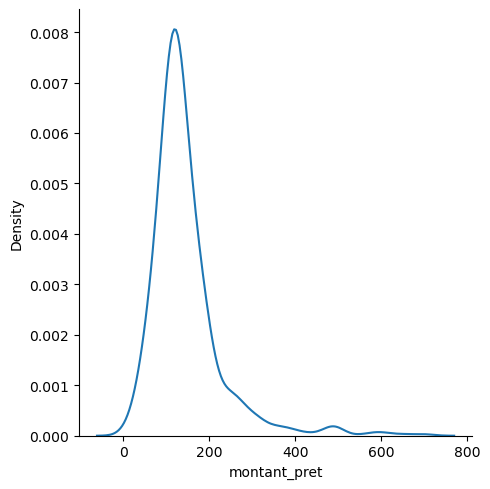

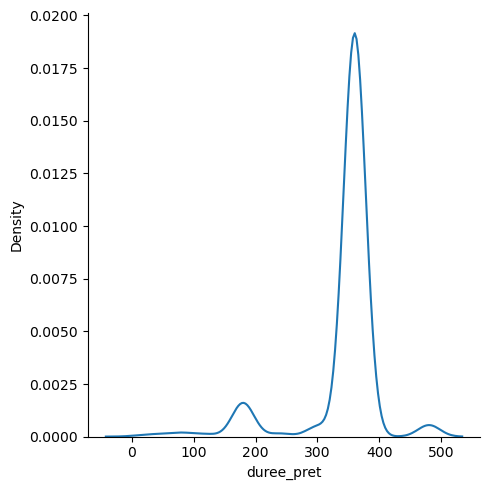

In [22]:
# Distributions
for col in name_col_num:
    sns.displot(data=df_num[col], kind='kde')

en générale, les observations montrent des asymetries fortement a droite dûes aux valeurs extremes et 
mais elles sont des distributions de loi normale.

# en conclusion:
les valeurs extremes ne sont pas des erreurs mais elles sont plausibles. 
Selon ce contexte, ces variables ne seront point winzorisées, ni cappées

# b-/ eme Niveau: Etude Bivarie

variable cible:  statut_pret

# notre plan: 
on cherche les liens, les patterns, les regles et les variables qui sont plus interessantes que d'autres.
nous allons proceder en phases:
- phase1 : etude de la variable cible avec des variables qualitatives : avec confirmation des tests stats chi2
- phase 2: etude de la variable cible avec des variables numeriques : avec confirmation des tests stats(shapiro, t-student, welch....)
- phase 3: etude multivariee : avec observation multivariée des pourcentages en fonction de chaque variable en fonction des autres 

# phase 1 : Etude bivariee de variables qualitatives

<Axes: xlabel='Education', ylabel='count'>

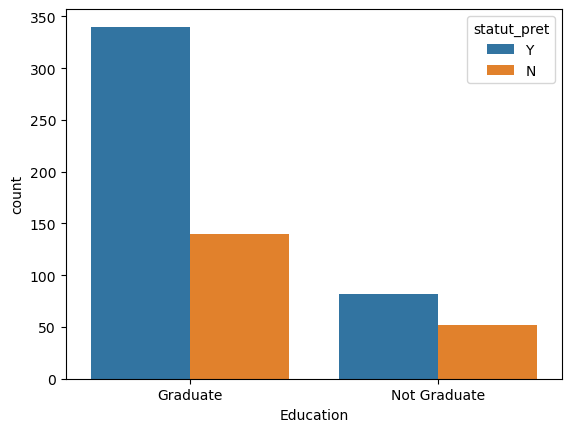

In [23]:
sns.countplot(data = df, hue='statut_pret', x='Education')

au sein des diplomes: la banque a plus accorde de credit que de refus : ---ci dessous en soit 70.08% 

au sein des non diplomes : la banque a plus accorde de credit que de refus: -- ci dessous soit 61.11%

ceci peut se confirmer par les pourcentages dans le tableau ci dessous :

In [24]:
pd.crosstab(df['statut_pret'], df['Education'], normalize='columns')

Education,Graduate,Not Graduate
statut_pret,,
N,0.291667,0.38806
Y,0.708333,0.61194


In [25]:
(pd.crosstab(df['statut_pret'], df['Education'], normalize='index')*100)

Education,Graduate,Not Graduate
statut_pret,,
N,72.916667,27.083333
Y,80.568720,19.431280


observation:
la banque a octroye plus de credit aux diplomes qu'au non diplomes: Soit 72.91% contre 27.08% respectivement

conclusion reflexive: existe t'il cette regle chez la banque:
-------------------------------------------------------------------------
es ce que la banque favorise l'octroi de credit chez les diplomes que chez les non diplomes ?
decision : Tests statistique : Khi-2

si on veut avoir une representation graphique, ci dessous :

<Axes: xlabel='statut_pret'>

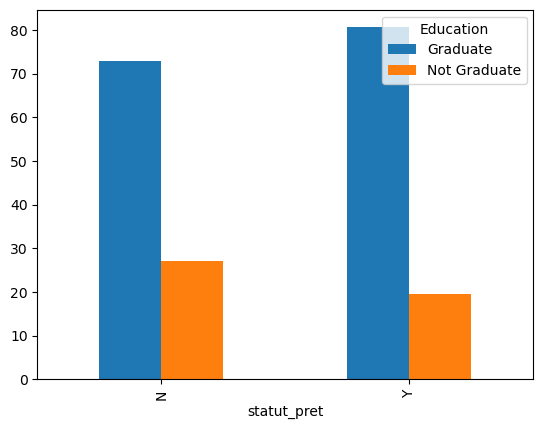

In [26]:
(pd.crosstab(df['statut_pret'], df['Education'], normalize='index')*100).plot(kind='bar')

In [27]:
# influence du statut sur les autres modalites des categorie : intra

for col in name_col_cat:
    graph = pd.crosstab(df['statut_pret'], df[col], normalize='index')*100
    print(f"\n{graph}\n")


genre           Female       Male
statut_pret                      
N            19.270833  80.729167
Y            17.772512  82.227488


marrie              No        Yes
statut_pret                      
N            41.145833  58.854167
Y            31.753555  68.246445


Education     Graduate  Not Graduate
statut_pret                         
N            72.916667     27.083333
Y            80.568720     19.431280


travailleur_indep         No        Yes
statut_pret                            
N                  86.458333  13.541667
Y                  86.729858  13.270142


zone_residence      Rural  Semiurban      Urban
statut_pret                                    
N               35.937500  28.125000  35.937500
Y               26.066351  42.417062  31.516588


credit_historique        0.0        1.0
statut_pret                            
N                  42.708333  57.291667
Y                   1.658768  98.341232



Observation:
--------------------------------------
1- plus d accords chez les males que chez les femmes: le fait d etre une femme defavorise a l'octroi du credit ?

2- plus d accords chez les maries que les celibatires : le fait d etre celibataire defavorise a l'octroi du credit ?

3- plus d accords chez les diplomes que les non diplomes : le fait d etre non diplomes defavorise a l'octroi du credit ?

4- plus d acords chez les travailleurs que les independants : le fait d etre independants defavorise a l'octroi du credit ?

5- plus d acords chez les semi-urbains que les rurals et urban : le fait de vivre en rural ou en urban defavorise a l'octroi du credit ?

6- plus d acords chez les personnes ayant deja eu un credit bancaire que ceux n ayant jamais eu : le fait d avoir un historique de credit defavorise a l'octroi du credit ?

NB: on pourra tester le lien qui ces variables pour chacune des question. Donc 07 tests statistiques de khi-2


# Confirmation / infimation des observations ci dessous: TESTS STATISTIQUES

In [28]:
from scipy.stats import chi2_contingency

In [29]:
def test_chi2 (x):
    alpha = 0.05
    chi2, p, dof, expected = chi2_contingency(x)
    print(f"chi2 :{chi2:.4f}")
    print(f"p-value : {p:.4f}")
    print(f"ddl: {dof:.4f}")

    if p < alpha:
        return (f"{p:.4f} < 0.05 : rejet H0 et H1: IL existe un lien")
    return f" NON REJET ---> H0: PAS lien |  p-value: {p:.4f} > {alpha} "

In [30]:
# les differentes tables de chaque tests

table_credit_genre = pd.crosstab(df['genre'], df['statut_pret'])
table_credit_marrie = pd.crosstab(df['marrie'], df['statut_pret'])
table_credit_Education = pd.crosstab(df['Education'], df['statut_pret'])
table_credit_travailleur_indep = pd.crosstab(df['travailleur_indep'], df['statut_pret'])
table_credit_zone_residence = pd.crosstab(df['zone_residence'], df['statut_pret'])
table_credit_credit_historique = pd.crosstab(df['credit_historique'], df['statut_pret'])

In [31]:
# existe t'il un lien entre l'ocrtoi de credit et le fait d'etre un homme ou une femme ?

test_chi2(table_credit_genre)

chi2 :0.1109
p-value : 0.7391
ddl: 1.0000


' NON REJET ---> H0: PAS lien |  p-value: 0.7391 > 0.05 '

In [32]:
# 2- existe t'il un lien entre l'ocrtoi de credit et le fait d'etre celibataire ?

test_chi2(table_credit_marrie)

chi2 :4.7319
p-value : 0.0296
ddl: 1.0000


'0.0296 < 0.05 : rejet H0 et H1: IL existe un lien'

In [33]:
# 3- existe t'il un lien entre l'ocrtoi de credit et le fait d'etre non-diplome ?

test_chi2(table_credit_Education)

chi2 :4.0915
p-value : 0.0431
ddl: 1.0000


'0.0431 < 0.05 : rejet H0 et H1: IL existe un lien'

In [34]:
# 4- existe t'il un lien entre l'ocrtoi de credit et le fait d'etre independant ?

test_chi2(table_credit_travailleur_indep)

chi2 :0.0000
p-value : 1.0000
ddl: 1.0000


' NON REJET ---> H0: PAS lien |  p-value: 1.0000 > 0.05 '

In [35]:
# 5- existe t'il un lien entre l'ocrtoi de credit et le fait de vivre en milieu semi-urbain ?

test_chi2(table_credit_zone_residence)

chi2 :12.2976
p-value : 0.0021
ddl: 2.0000


'0.0021 < 0.05 : rejet H0 et H1: IL existe un lien'

In [36]:
# 6- existe t'il un lien entre l'ocrtoi de credit et le fait d'avoir deja eu un historique de credit ?

test_chi2(table_credit_credit_historique)

chi2 :176.1146
p-value : 0.0000
ddl: 1.0000


'0.0000 < 0.05 : rejet H0 et H1: IL existe un lien'

CONCLUSION RECAPITULATIVE des tests statistiques:

- Octroi de credit et genre : pas de lien
- Octroi credit et marrie : existence de lien
- Octroi credit et Education : existence de lien
- Octroi credit et travailleur Independant : PAS de lien
- Octroi credit et ZONE_RESIDENCE : existence de lien
- Octroi credit et credit_historique : existence de lien

les variables a plus creuser pour la continuité est Marrié , Education , Zone de residence , Credit historique

# phase 2: Analyse bivariee : variables QUANTITATIVES ET VARIABLE CIBLE 

In [37]:
# Statistique par groupe de variable cible: non accorder = 0 accorder = 1

df.groupby(by='statut_pret')[name_col_num].mean().T

statut_pret,N,Y
pers_en_charge,0.729167,0.751185
revenu_demandeur,5446.078125,5384.068720
revenu_codemmandeur,1877.807292,1504.516398
montant_pret,149.890625,143.869668
duree_pret,344.562500,341.431280


les differentes variables n'ont pas le meme effet sur l'octroi de credit ou non car les moyennes differentes sont significativement differentes
cela peut etre confirmer par le test sur les moyennes.

# TESTS A OPERER 

1- Es ce les demandeurs ayant une charge ont un effet different sur l'octroi de credit ?

2- Es ce les demandeurs ayant un revenu ont un effet different sur l'octroi de credit ?

3- Es ce les demandeurs ayant un co_revenu ont un effet different sur l'octroi de credit ?

4- Es ce les montants demandés ont un effet different sur l'octroi de credit ?

5- Es ce la duree de pret ont un effet different sur sur l'octroi de credit ?


il faut recueillir toutes les valeurs par modalites de chaque variable pour faire ce tests quantitatifs

In [38]:
from scipy.stats import chi2_contingency
from scipy.stats import stats
from scipy.stats import shapiro, levene, ttest_ind, mannwhitneyu, bartlett, f_oneway, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

In [39]:
df.statut_pret.unique()

<StringArray>
['Y', 'N']
Length: 2, dtype: str

In [40]:
print("H0:  moy1 = moy2 : Pas de difference de moyennes ")
print("h1: moy1 # moy 2:  Difference de moyennes ")

alpha = 0.05

for var in name_col_num:
        
    NON = df[df['statut_pret']=='N'][var].dropna()
    YES = df[df['statut_pret']=='Y'][var].dropna()
    stats, pvalue = ttest_ind(NON, YES, equal_var=False)

    # affichage
    print(f"\n==============================================================================================")
    print(f"\n===> la variable {var} etant deja normale: Donc test de welch t-test <===")
    print(f"\n{var}")
    print(f"Moyenne N: {NON.mean().round(2)}")
    print(f"Moyenne Y:{YES.mean().round(2)}")
    print(f"p-value: {pvalue.round(2)}")

    # affichage selon le resultats de pvalue
    if pvalue < alpha:
        print(f"{pvalue} < {alpha} : rejet H0")
        print("il existe une difference")
        
    else:
        print(f"{pvalue} > {alpha} : PAS de rejet H0")
        print("il n'existe pas une difference")
        
    

H0:  moy1 = moy2 : Pas de difference de moyennes 
h1: moy1 # moy 2:  Difference de moyennes 


===> la variable pers_en_charge etant deja normale: Donc test de welch t-test <===

pers_en_charge
Moyenne N: 0.73
Moyenne Y:0.75
p-value: 0.8
0.80272169085343 > 0.05 : PAS de rejet H0
il n'existe pas une difference


===> la variable revenu_demandeur etant deja normale: Donc test de welch t-test <===

revenu_demandeur
Moyenne N: 5446.08
Moyenne Y:5384.07
p-value: 0.91
0.9129148547301199 > 0.05 : PAS de rejet H0
il n'existe pas une difference


===> la variable revenu_codemmandeur etant deja normale: Donc test de welch t-test <===

revenu_codemmandeur
Moyenne N: 1877.81
Moyenne Y:1504.52
p-value: 0.26
0.25914349433282663 > 0.05 : PAS de rejet H0
il n'existe pas une difference


===> la variable montant_pret etant deja normale: Donc test de welch t-test <===

montant_pret
Moyenne N: 149.89
Moyenne Y:143.87
p-value: 0.41
0.40970790413583597 > 0.05 : PAS de rejet H0
il n'existe pas une differenc

CONCLUSION:

la difference de moyennes observé au sein des personnes qu'on octroie le credit et ceux dont on n'octroient pas de credit est signifcativement identique. 

# Visuqlisqtion des Graphiques: la variable cible et variables quantitatives

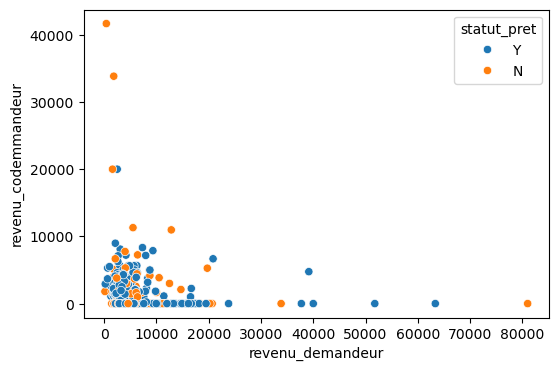

In [41]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x = 'revenu_demandeur', y= 'revenu_codemmandeur',  hue='statut_pret',markers=True)
plt.show()

les codemandeurs ayant un revenu entre 0 -20k ont plus ou moins du credit accordé si la demande est autour de 0 -20k.
il existe uun petit groupe qui ont des revenus de codemandeurs tres bas mais ayant obtenu des revenus superieurs a 20k soit situe entre 40k - 65k qui est la limite pour cette petite categorie

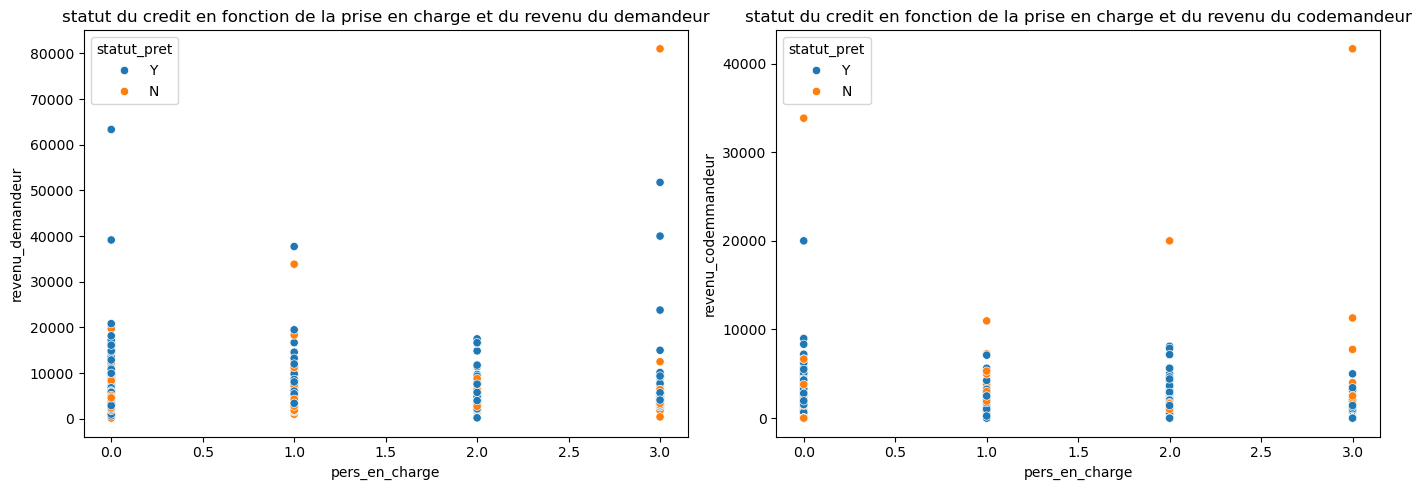

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x = 'pers_en_charge', y= 'revenu_demandeur',  hue='statut_pret',markers=True, ax = axes[0])
axes[0].set_title('statut du credit en fonction de la prise en charge et du revenu du demandeur')


b = sns.scatterplot(data=df, x = 'pers_en_charge', y= 'revenu_codemmandeur',  hue='statut_pret',markers=True)
axes[1].set_title('statut du credit en fonction de la prise en charge et du revenu du codemandeur')

plt.tight_layout()
plt.show()

A comparaison egale, on observe que :
le revenu du demandeur est plus pesant par rapport au revenu du codemandeur dans l'octroi du credit 
pour les demandeurs ayant ou non les personnes en charges

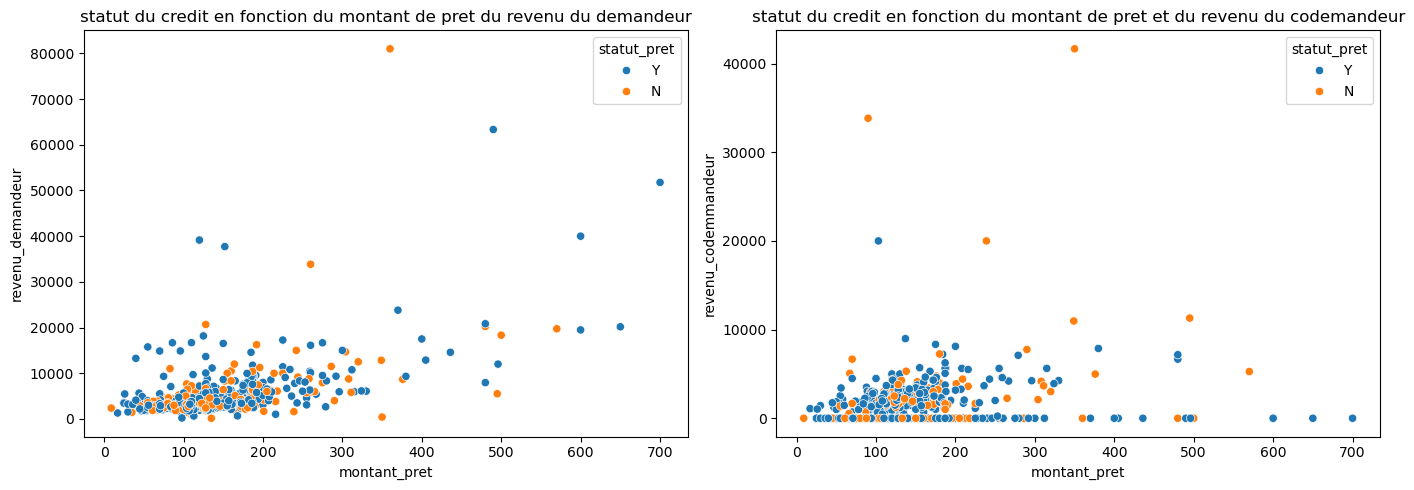

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x = 'montant_pret', y= 'revenu_demandeur',  hue='statut_pret',markers=True, ax = axes[0])
axes[0].set_title('statut du credit en fonction du montant de pret du revenu du demandeur')


b = sns.scatterplot(data=df, x = 'montant_pret', y= 'revenu_codemmandeur',  hue='statut_pret',markers=True)
axes[1].set_title('statut du credit en fonction du montant de pret et du revenu du codemandeur')

plt.tight_layout()
plt.show()

les montants compris entre 0 et 500k sont les sommes les plus demandées pour les demandeurs et codemandeurs ayant un revenu compris entre 0 et 20k. 

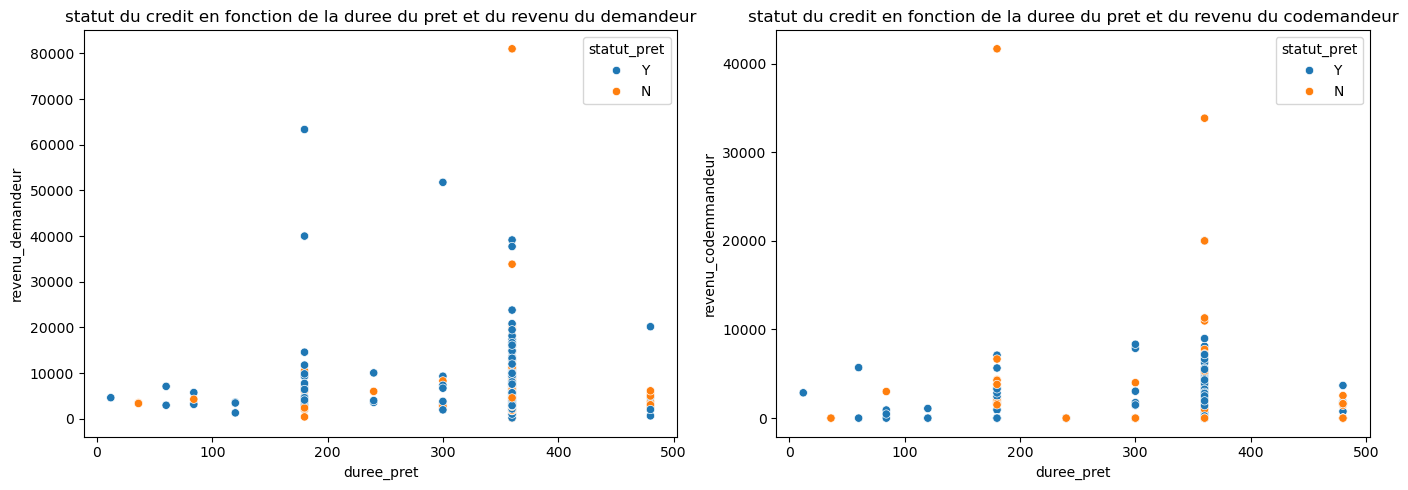

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x = 'duree_pret', y= 'revenu_demandeur',  hue='statut_pret',markers=True, ax = axes[0])
axes[0].set_title('statut du credit en fonction de la duree du pret et du revenu du demandeur')


sns.scatterplot(data=df, x = 'duree_pret', y= 'revenu_codemmandeur',  hue='statut_pret',markers=True)
axes[1].set_title('statut du credit en fonction de la duree du pret et du revenu du codemandeur')

plt.tight_layout()
plt.show()

il semble avoir deux groupes interessant : un groupe dont la duree du pret est proche de 200 mois et dont le revenu du demandeur est situe entre 1k et 40 k.
le deuxieme groupe estt celui dont le nombre de mois est situé est 370 mois avec un revenu du demandeur situe entre 0 et 40k. quelques ecarts sont observees 

ce graphique est presque similaire a celui revenu du demandeur et la duree.
ainsi, on observe toujours ces memes deux groupes qui sont assez representé. le revenu du codemandeur joue un role important dans l'octroi du credit.

observation simultannee de ces graphes presentent:

- a des memes positions identiques : l'une des deux variables a peser dans l'octroi de credit et parfois les deux variables ont ete d'un poids commun a l octroi de credit.



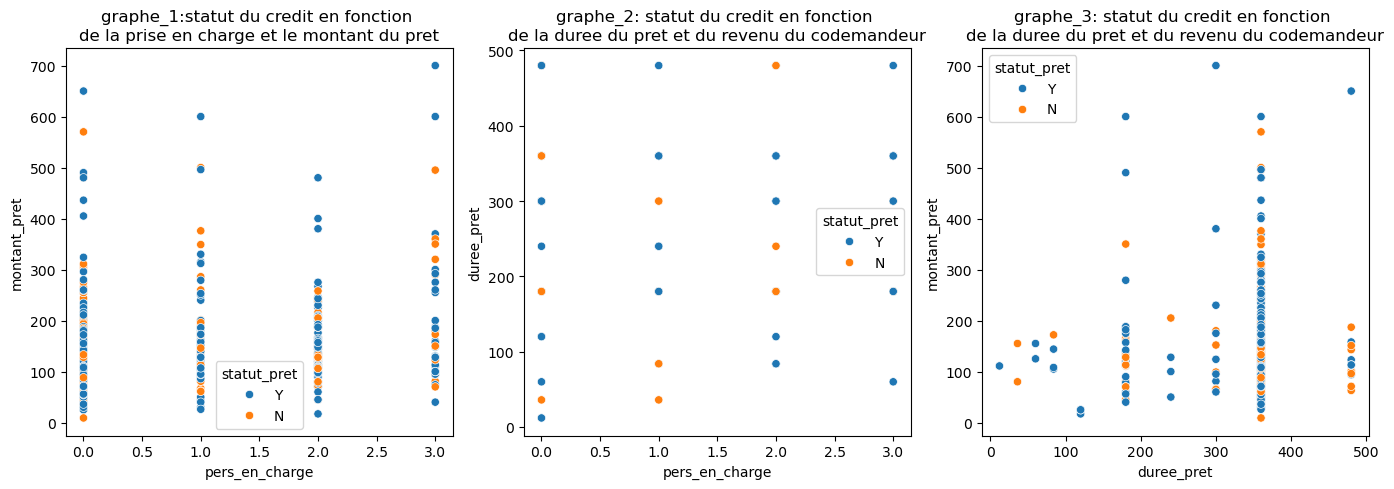

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

sns.scatterplot(data=df, x = 'pers_en_charge', y= 'montant_pret',  hue='statut_pret',markers=True, ax=axes[0])
axes[0].set_title('graphe_1:statut du credit en fonction \nde la prise en charge et le montant du pret')

sns.scatterplot(data=df, x = 'pers_en_charge', y= 'duree_pret',  hue='statut_pret',markers=True, ax=axes[1])
axes[1].set_title('graphe_2: statut du credit en fonction \nde la duree du pret et du revenu du codemandeur')

sns.scatterplot(data=df, x = 'duree_pret', y= 'montant_pret',  hue='statut_pret',markers=True,ax=axes[2])
axes[2].set_title('graphe_3: statut du credit en fonction \nde la duree du pret et du revenu du codemandeur')


plt.tight_layout()
plt.show()

# graphe_1: 
ce graphe montre que l'on a accordé du credit aux demandeurs ayant 1; 2; ou 3 personnes en charges.
par ailleurs, les demandeurs sont en majorité sans enfant et semble etre les plus nombreux a avoir obtenu un pret.

# graphe 2:
Les demandeurs ayant 3 personnes en leur charge ont tous des credits accordee peu importe 
la duree du remboursement du pret

# graphe 3:
les montants de pret varient entre 1 a 700k.
on constacte que les personnes avec des differentes charges demandent ces montants compris dans cet intervalle.
cependant, on peut constater qu'il y a plus d'octroi que de refus.
on peut aussi constater que le nombre de demande est eleve chez les demandeurs ayant 03 personnes en leur charge en premier et en second chez les demandeurs sans charge.
les credits les plus accordés sont autour d'une duree de de 370 mois

# conclusion :variable cible et variables quantitatives 

plusieurs variables interessantes sont a considerer : le montant du pret, le revenu du demandeur et du codemandeur, les personnes prises en charges

# c-/ Analyse Multivariée

<Axes: xlabel='genre,Education'>

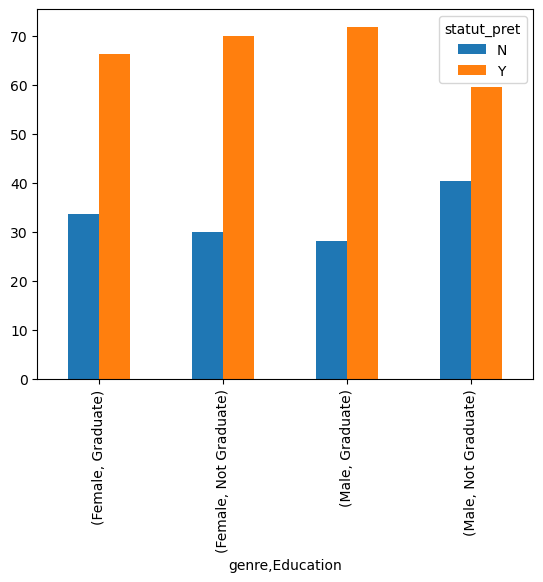

In [46]:
# importance de variable entre genre,education par rapport au statut du pret

(pd.crosstab([df['genre'], df['Education']],  df['statut_pret'],
            normalize='index')*100).plot(kind="bar")

regle 1:

le fait d'etre une femme ou un homme ayant fait les etudes ou non montre un pourcentage d'octroi de credit plus eleve que les refus.

<Axes: xlabel='genre,Education,credit_historique'>

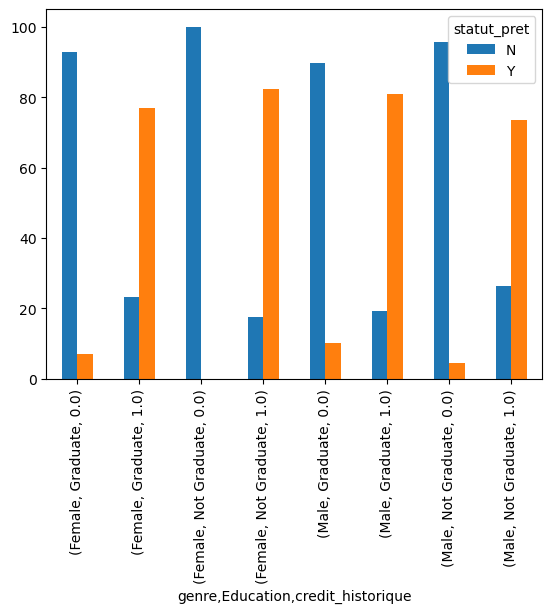

In [47]:
(pd.crosstab([df['genre'], df['Education'], df['credit_historique']],  df['statut_pret'],
            normalize='index')*100).plot(kind="bar")

regle 2: 

- le fait d etre un homme/femme et ayant fait des etudes/non mais n'ayant pas de credit historique montrent moins de chance d'avoir un credit accordé. 
- A l'inverse, un homme/femme diplomé/non avec un credit historique donne plus de chance d'avoir un credit accordé.

<Axes: xlabel='genre,Education,credit_historique,zone_residence'>

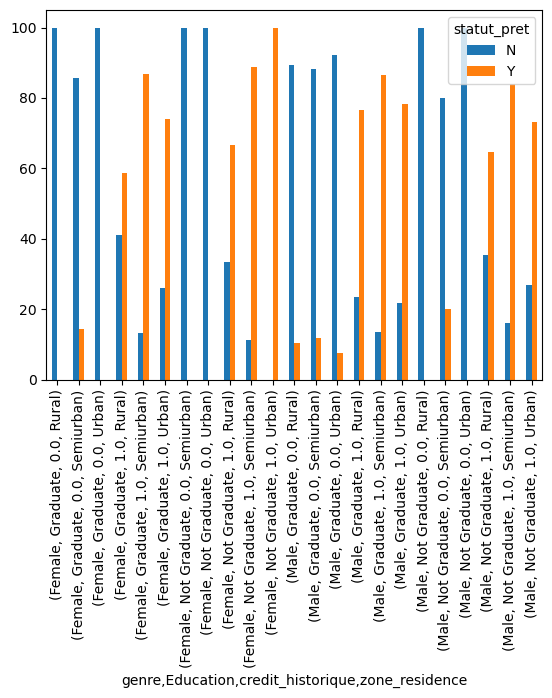

In [48]:
(pd.crosstab([df['genre'], df['Education'], df['credit_historique'], df['zone_residence']],  df['statut_pret'],
            normalize='index') *100 ).plot(kind="bar")

regle 3:

1- femelle diplomé/non sans credit historique et vivant en milieu rural a 100% de chance de n'avoir pas de credit accordé

2- homme non diplomé sans credit historique/non  et vivant en milieu rural a 100% de chance de n'avoir pas de credit accordé

3- une femme sans education ayant un credit historique et vivant en milieu rural a 100% de chances d'obtenir un credit

4- un homme diplomé/non ayant un credit/non vivant en milieu rural/semi-urbain a plus de chance d'obtenir du credit

5- un homme diplomé avec un historique de credit en milieu rural/semi_urbain/urban a plus de chance d'obtenir du credit

5- par contre, un homme diplomé sans credit historique en milieu rural/semi_urbain/urban a moins de chance d'obtenir du credit

<Axes: xlabel='genre,Education,credit_historique,zone_residence,travailleur_indep'>

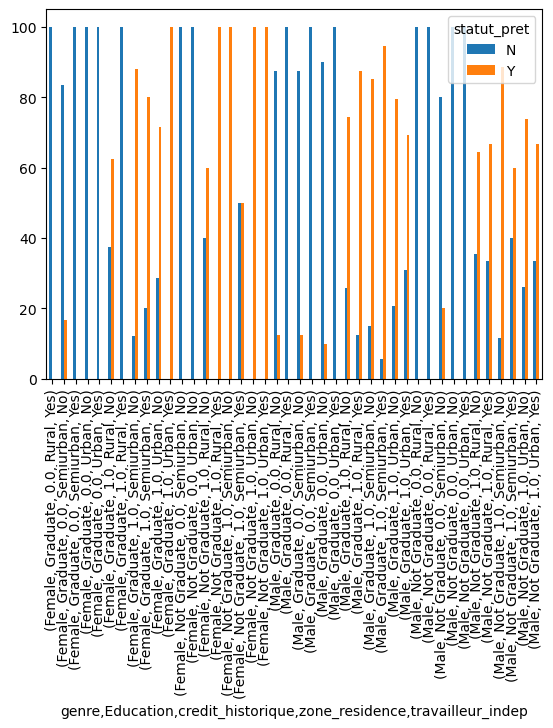

In [49]:
(pd.crosstab([df['genre'], df['Education'], df['credit_historique'], df['zone_residence'], df['travailleur_indep']],  df['statut_pret'],
            normalize='index') *100 ).plot(kind="bar")

# 4- BENCHNMARKING DES MODELES

Objectif: Voir les modeles les plus competitifs pour etre sur de choisir la meilleure performance de tous les modèles

# Rappel :
- variables numeriques : ---> StandardScaler() 
- variables categorielles: --> OneHotEncoder()
- variables categorielles : ---> OrdinalEncoder()
- variable cible y : uniquement ---> LabelEncoder()

# Rappel : Eviter Data Leakage
- Nous allons uniquement travailler sur 80% des donnees de l'entrainement
- si nos modeles sont tres concurents, on doit choisir 03 modeles ou 04 modeles: les meilleurs
- on doit faire de l'optimisation sur ceux ci: feature selection, feature enginnerring, evaluation initial sur 80%, optimisation des hyperparametres + cv
- choix du modele final: utilisation de 20% des donnees tests

In [50]:
# copie du df_bench

df_bench = df.copy()

df_bench.head(1)

,genre,marrie,pers_en_charge,Education,travailleur_indep,revenu_demandeur,revenu_codemmandeur,montant_pret,duree_pret,credit_historique,zone_residence,statut_pret
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y


In [51]:
# separtion des variables indeoendantes de la variable dependante(ou variabe cible)

X = df_bench.drop(columns='statut_pret')
y = df_bench['statut_pret']

In [52]:
# Division du dataset en df_train(X_train, y_test) et df_set(X_test et y_test) de maniere repartie egale de classes 

from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [53]:
# encodage des modalites categorielles par des chiffres: variable cible y soit (y_train, y_test)

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [55]:
# differents modèles pour le BenchMarking

models = {
    'Logistic_regression' : LogisticRegression(random_state = 42),
    'KNeighborsClassifier' : KNeighborsClassifier(),
    'DecisionTreeClassifier' : DecisionTreeClassifier(random_state=42),
    'RandomForestClassifier' : RandomForestClassifier (random_state=42),
    'ExtraTreesClassifier' : ExtraTreesClassifier(random_state=42),
    'XGBoost' : XGBClassifier(),
    'AdaBoost' : AdaBoostClassifier(random_state=42),
    'SVC' : SVC(random_state=42),
    'Naives_Bayes' : GaussianNB(),
    'LightGBM': LGBMClassifier(random_state=42),
    'CatBoost' : CatBoostClassifier(random_state=42)
}

In [56]:
# Importqation librairie pour l' évaluation des modèles
from sklearn.model_selection import (cross_val_score, cross_validate)

# les metriques de mesures des modèles
from sklearn.metrics import make_scorer,accuracy_score, f1_score, recall_score, roc_auc_score, precision_score, mean_squared_error, mean_absolute_error

metrics = {
    'accuracy' : make_scorer(accuracy_score),
    'roc_auc' : make_scorer(roc_auc_score),
    'recall' : make_scorer(recall_score),
    'f1' :make_scorer(f1_score),
    'precision' : make_scorer(precision_score)
}

In [57]:
#  transformers des colonnes : creation du preprocessing ==> automatiquement sclaer et encoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline

# stockage des resultats
resultat = []

# Evaluation des modeles: score_validate
for name, model in models.items():
    preprocessor = ColumnTransformer(transformers=[
        ('num', RobustScaler(), name_col_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), name_col_cat)   ])
    
    pipeline = Pipeline([ ('preprocessing', preprocessor), ('model', model)] )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metrics)
    resultat.append({
        'modele':name,
        'accuracy': scores['test_accuracy'].mean(),
        'roc_auc' : scores['test_roc_auc'].mean(),
        'recall' : scores['test_recall'].mean(),
        'f1' : scores['test_f1'].mean(),
        'precision' : scores['test_precision'].mean(),
        'stabilite' : scores['test_accuracy'].std()
    })

# Créqtion du dataframe propre a l'Affichage
bench = pd.DataFrame(resultat)
bench_resultat = bench.sort_values(by = ["recall", 'precision' ], ascending = True)
print(bench_resultat)

C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

[LightGBM] [Info] Number of positive: 269, number of negative: 123
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000242 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 318
[LightGBM] [Info] Number of data points in the train set: 392, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.686224 -> initscore=0.782527
[LightGBM] [Info] Start training from score 0.782527
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\PC\anaconda3\envs\data_science\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 270, number of negative: 123
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000147 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 321
[LightGBM] [Info] Number of data points in the train set: 393, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.687023 -> initscore=0.786238
[LightGBM] [Info] Start training from score 0.786238
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

# filtre des resultats selon nos metriques d'apres notre contexte metier 'recall' et 'precision'

In [58]:
bench = pd.DataFrame(resultat)
bench_resultat = bench.sort_values(by = ['roc_auc', 'recall', 'precision'], ascending = False)
print(bench_resultat)

                    modele  accuracy   roc_auc    recall        f1  precision  \
9                 LightGBM  0.778005  0.709762  0.893503  0.846897   0.807441   
8             Naives_Bayes  0.790188  0.690592  0.958604  0.862820   0.785500   
10                CatBoost  0.790146  0.690377  0.958604  0.862805   0.785397   
6                 AdaBoost  0.794187  0.689808  0.970369  0.866403   0.783118   
0      Logistic_regression  0.796248  0.689523  0.976251  0.868443   0.782579   
3   RandomForestClassifier  0.773861  0.682035  0.929017  0.849557   0.783819   
5                  XGBoost  0.753597  0.681432  0.875768  0.829570   0.791657   
2   DecisionTreeClassifier  0.727128  0.677609  0.810272  0.803107   0.796971   
4     ExtraTreesClassifier  0.749392  0.673008  0.878490  0.827661   0.783570   
1     KNeighborsClassifier  0.731251  0.624610  0.911370  0.822639   0.750836   
7                      SVC  0.680251  0.497300  0.988147  0.809189   0.685162   

    stabilite  
9    0.0480

voici nos modeles concurrents

                    modele  accuracy   roc_auc    recall     f1      precision   stabilite
9                 LightGBM  0.778005  0.709762  0.893503  0.846897   0.807441   0.048024
8             Naives_Bayes  0.790188  0.690592  0.958604  0.862820   0.785500   0.040262
10                CatBoost  0.790146  0.690377  0.958604  0.862805   0.785397   0.047525
6                 AdaBoost  0.794187  0.689808  0.970369  0.866403   0.783118   0.041922 

NB: plus notre recall monte plus la precision diminue 

# 5- / STRATEGIE DE CHOIX DU MODELE FINAL: 
Nous allons uniquement travailler sur le train_set (80% des données).
Nous allons appliquer cette etape sur nos 04 modèles retenues.
Les analyses sont les suivantes: 

# Etablir la Baseline du modele
- Definition du contexte Metier: tress important(Squelette de tout le travail)
  
- encoder nos variables X_train et il faut noter que y_train a deja été encodé

- Verification du deséquilibre des classes du dataset : si desequilibré ? possibilié d'utiliser class_weight = 'balanced '

- prediction OOF des 04 modeles + matrice de de confusion(cm) + classification report(CR) : pour avoir une baseline de modèle pour l'evaluation des 04 modèles

- Analyse FP / FN d'apres les resultats de prediction_OOF + cm + CR

# strategie pour choisir le modèle final sur les 04 
- Analyse des seuils et des liens entre FP et FN pour choisir un seuil optimal de chaque modèle: appliquer a chaque seuil_optimal a chaque modele et reévaluer le modele de nouveau pour voir le meilleur
  
- Analyse du cout de l'erreur de chaque modèle: prendre le modèle qui a la plus pétite erreur

-  la methode de class_weight pour chaque modèle : reévaluer les 04 modèles de nouveau pour voir le meilleur.

- comparer les resultats obtenus de chaque modèle avec le seuil_optimal et avec class_weight: celui qui l'emporte est appliquer pour la suite

- Choisir le modele final pour passer a l'etape de feature selection.

# a- / Définition du contexte Metier

la Banque s'est rendu compte qu'elle octroiyait plus de credit mais dans la réalité des faits, la banque a constaté un deficit de performance dans la sovabilité des prets accordés aux demandeurs. Alors, elle souhaite concevoir ce systeme de decision qui les aident a réduire les octroye de crédit aux demandeurs non solvables.
elle note qu'une non solvabilté lui coute 10 fois qu'une perte d'un client solvable a qui l'on a refusé un pret.
la banque a fournit ses données sur leur activité  de crédit qui est notre base de données.

en traduction du domaine de data_science: les elements suivants designent cette situation

TP(True positifs) : personnes réellement solvables
TN(True Négatifs) : personnes réellement non-solvables 
FP(Faux Positifs) : personnes non-solvables qui ont eu un crédit
FN(Faux négatif) : personnes solvables a qui on a réfusé du crédit.

notre variable cible: statut_pret : qui comporte deux modalités (0, 1) representant respectivement la classe 0 = refus de crédit et la classe 1 = accord du crédit.

# a-/ Preprocessing sur nos données X_train et X_test

In [59]:
# creeons le shape les X_train et X_test encoded a utiliser

def preprocessing(X_train, X_test, col_num, col_cat):
    preprocessor = ColumnTransformer(transformers=[
        ('num', RobustScaler(), col_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), col_cat)
        
    ])

    X_train_encoded = preprocessor.fit_transform(X_train)
    X_test_encoded = preprocessor.transform(X_test)

    features_names = preprocessor.get_feature_names_out()

    X_train_encoded = pd.DataFrame(X_train_encoded, columns=features_names, index=X_train.index)
    X_test_encoded = pd.DataFrame(X_test_encoded, columns=features_names, index=X_test.index)

    return (X_train_encoded, X_test_encoded, preprocessor, features_names)

In [60]:
X_train_encoded, X_test_encoded, preprocessor, features_names = preprocessing(X_train, X_test, name_col_num, name_col_cat)

In [61]:
print("\nDimension de X_train:", X_train.shape)
print("Dimension de X_train_encoded:", X_train_encoded.shape)
print("\nDimension de X_test: ", X_test_encoded.shape)
print("Dimension de X_test_encoded: ", X_test_encoded.shape)
print("\nnom des variables encoded:", features_names)


Dimension de X_train: (491, 11)
Dimension de X_train_encoded: (491, 18)

Dimension de X_test:  (123, 18)
Dimension de X_test_encoded:  (123, 18)

nom des variables encoded: ['num__pers_en_charge' 'num__revenu_demandeur' 'num__revenu_codemmandeur'
 'num__montant_pret' 'num__duree_pret' 'cat__genre_Female'
 'cat__genre_Male' 'cat__marrie_No' 'cat__marrie_Yes'
 'cat__Education_Graduate' 'cat__Education_Not Graduate'
 'cat__travailleur_indep_No' 'cat__travailleur_indep_Yes'
 'cat__zone_residence_Rural' 'cat__zone_residence_Semiurban'
 'cat__zone_residence_Urban' 'cat__credit_historique_0.0'
 'cat__credit_historique_1.0']


# b- desequilibre des classes

In [62]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (confusion_matrix, classification_report, 
average_precision_score, precision_recall_curve, roc_curve )

In [63]:
# Jauger le desequilibre/equilibre des classes : importants pour la strategie des modeles

classes,effectifs = np.unique(y_train,return_counts=True)
proportions = effectifs / len(y_train)*100
print(f"Classes : {classes} \nEffectifs: {effectifs} \nProportions en %: {proportions.round(2)}")

Classes : [0 1] 
Effectifs: [154 337] 
Proportions en %: [31.36 68.64]


ces resultats montrent un certain desequilibre.
le modele aurait tendance de predire 68.64 % la classe 1 et ce , sans avoir meme commencer a apprendre.
d'ou l'accuracy ne peut pas etre consideré au plus.

- ce rapport 68/32 est notre baseline pour nos modeles : nos modeles tournent autour de 70-80 % soit une Valeur ajoutee de +10%
- ces proprotions nous indiquent de choisir PR-AUC plutot que AUC : Car notre modele fait plus de Faux Positifs qui est ce que nous voulons reduire ie accorder du credit a des non-solvables. ce PR-AUC va le reduire alors que AUC ey est trop optimiste.
- certains modeles comme XGboost / Catboost minisent l'erreur globale donc ont plus predire la classe majoritaire ici classe 1.
- elle va nous servir a l'etape d'ajustement du seuil, couts des erreurs, calibrage des probabilites et interpretation metier

# c-/ Etablir la Baseline du modele

In [64]:
# predictions OOF 
modelee = {
    'LightGBM': LGBMClassifier(random_state=42, verbiosity=-1),
    'Naives Bayes' : GaussianNB(),
    'CatBoost' : CatBoostClassifier(random_state=42, verbose=0),
    'AdaBoost' : AdaBoostClassifier(random_state=42 )
}

In [65]:
# Predictions OOF = Out-Of-Fold : objectif: predictions honnetes sur nos 80 % de donnees

predictions_oof = {}

print('lancement de predictions oof')

for nom, modele in modelee.items():

    # prediction des classes : predictions avec accord ou refus a un seuil par defaut de 0.5
    y_train_pred = cross_val_predict(modele, X_train_encoded, y_train, 
                                     cv=cv, method='predict', n_jobs=-1)

    # prediction des probabilites:  probabilite du modele a etre sur
    y_proba = cross_val_predict(modele, X_train_encoded, y_train, 
                                cv=cv, method='predict_proba', n_jobs=-1)[:,1]
    
    predictions_oof[nom] = {
        'y_train_pred': y_train_pred,
        'y_proba' : y_proba
    }

print(f"{len(y_train_pred)} predictions generees")
print("Modeles predits:", list(predictions_oof.keys()))

lancement de predictions oof
491 predictions generees
Modeles predits: ['LightGBM', 'Naives Bayes', 'CatBoost', 'AdaBoost']


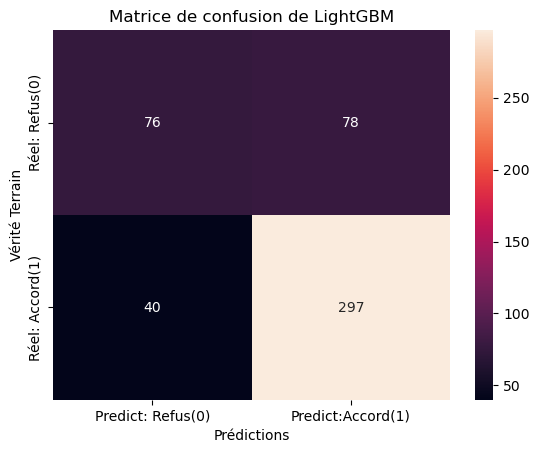


*****Matrice de confuson: LightGBM ***************************************
Bon Accord:297
Accord a tort 78
Bons refus : 76
Refus a tort : 40

*****Classification Report : LightGBM ***************************************
              precision    recall  f1-score   support

           0       0.66      0.49      0.56       154
           1       0.79      0.88      0.83       337

    accuracy                           0.76       491
   macro avg       0.72      0.69      0.70       491
weighted avg       0.75      0.76      0.75       491



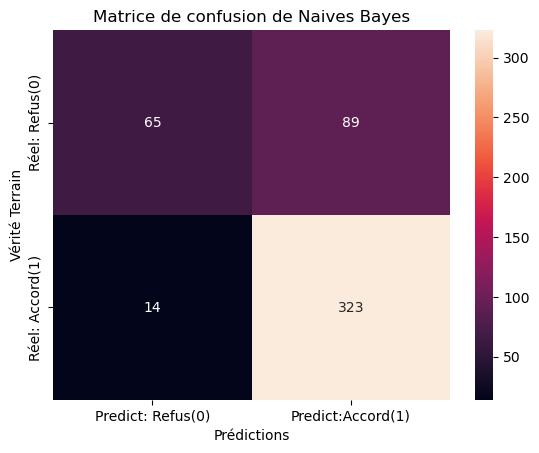


*****Matrice de confuson: Naives Bayes ***************************************
Bon Accord:323
Accord a tort 89
Bons refus : 65
Refus a tort : 14

*****Classification Report : Naives Bayes ***************************************
              precision    recall  f1-score   support

           0       0.82      0.42      0.56       154
           1       0.78      0.96      0.86       337

    accuracy                           0.79       491
   macro avg       0.80      0.69      0.71       491
weighted avg       0.80      0.79      0.77       491



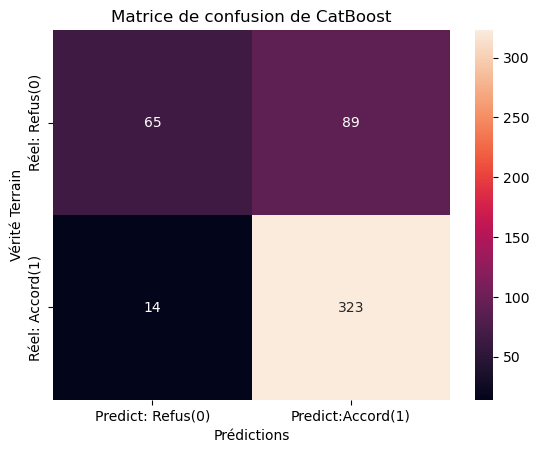


*****Matrice de confuson: CatBoost ***************************************
Bon Accord:323
Accord a tort 89
Bons refus : 65
Refus a tort : 14

*****Classification Report : CatBoost ***************************************
              precision    recall  f1-score   support

           0       0.82      0.42      0.56       154
           1       0.78      0.96      0.86       337

    accuracy                           0.79       491
   macro avg       0.80      0.69      0.71       491
weighted avg       0.80      0.79      0.77       491



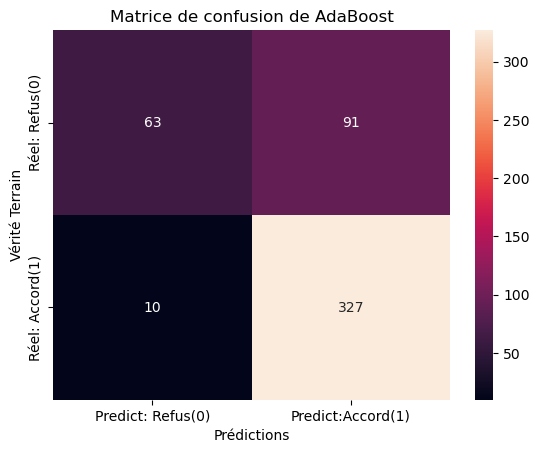


*****Matrice de confuson: AdaBoost ***************************************
Bon Accord:327
Accord a tort 91
Bons refus : 63
Refus a tort : 10

*****Classification Report : AdaBoost ***************************************
              precision    recall  f1-score   support

           0       0.86      0.41      0.56       154
           1       0.78      0.97      0.87       337

    accuracy                           0.79       491
   macro avg       0.82      0.69      0.71       491
weighted avg       0.81      0.79      0.77       491



In [66]:
# Matrice de confusion et rapport de classification----propose les predictions et les precisions pour chaque classe
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

for name, resultats in predictions_oof.items():
    y_train_pred = resultats['y_train_pred']
    cm = confusion_matrix(y_train, y_train_pred)
    tn, fp, fn, tp = cm.ravel()
    
    sns.heatmap(cm, annot=True, fmt='d',
           xticklabels=["Predict: Refus(0)", "Predict:Accord(1)"],
           yticklabels=["Réel: Refus(0)", "Réel: Accord(1)"])

    # affichage de la matrice
    plt.title(f"Matrice de confusion de {name}")
    plt.ylabel("Vérité Terrain")
    plt.xlabel("Prédictions")
    plt.show()

    
    # affichage de valeurs en texte
    print(f"\n*****Matrice de confuson: {name} ***************************************")
    print(f"Bon Accord:{tp}")
    print(f"Accord a tort {fp}")
    print(f"Bons refus : {tn}")
    print(f"Refus a tort : {fn}")

    # affcihage de Classification report
    print(f"\n*****Classification Report : {name} ***************************************")
    print(classification_report(y_train, y_train_pred))
    
   

conclusion : 
selon le contexte metier defini deja, ces deux elements devraientg etre les plus petits possible

                    LightBoost    Naives Bayes   CatBoost  AdaBoost        cout
FP = Accord a tort:     78            89         89         91         risque = perte
FN = Refus a tort :     40            14         14         10         manque a gagner=Economique
TN = Bon Refus :        297           323        323        327
TP = Bon accord :       76            65         65         63
 



possibilite de choix : ici nous pouvons passer a l'etape de feature selection + enginerring + hyperparametre

Nou svoulons encore creuser pour pouvoir avoir des distinction qui peuvent nous permettre de choisir un seul modèle final deja a cette etape: analyse de seuil, l'analyse de couts pour le modele qui reduit au plus, utilisation a cause du desequilibre: class_weight = 'balanced ' comme énonce au grand titre.

# d- analyse de seuil

In [67]:
# graphique des FP et FN de chaque modele
seuils = np.arange(0.01, 1.00, 0.01)
data_seuils = {}
for nom, data in predictions_oof.items():
    fp_list, fn_list = [], []
    for s in seuils:
        y_train_pred = (data["y_proba"] >= s).astype(int)
        CM = confusion_matrix(y_train, y_train_pred)
        tn, fp, fn, tp = CM.ravel()
        fp_list.append(fp)
        fn_list.append(fn)

        data_seuils[nom] = {
            'fp' : fp_list,
            'fn' : fn_list
        }

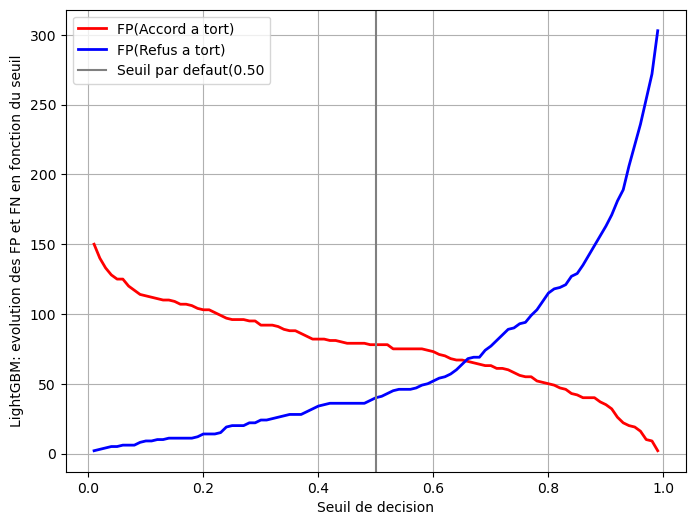

In [68]:
# graphique 1: de FP et FN pour LighGBM(le meilleur score)
plt.figure(figsize=(8,6))

data = data_seuils['LightGBM']

plt.plot(seuils, data['fp'], label='FP(Accord a tort)', color='red', linewidth=2)
plt.plot(seuils, data['fn'], label='FP(Refus a tort)', color='blue', linewidth=2)

plt.axvline(x=0.50,color='grey', label='Seuil par defaut(0.50')
plt.xlabel('Seuil de decision')
plt.ylabel('LightGBM: evolution des FP et FN en fonction du seuil')
plt.legend()
plt.grid(True)
plt.show()


pour LightBoost: le meilleur seuil compromis qui minimise les FP(Accord a tort) et limite les refus a tortest autour de 0.64 

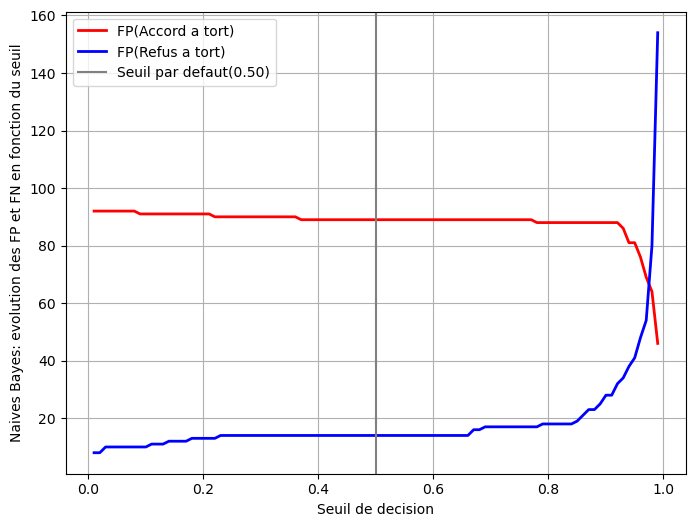

In [69]:
# graphique 1: de FP et FN pour LighGBM(le meilleur score)
plt.figure(figsize=(8,6))

data = data_seuils['Naives Bayes']

plt.plot(seuils, data['fp'], label='FP(Accord a tort)', color='red', linewidth=2)
plt.plot(seuils, data['fn'], label='FP(Refus a tort)', color='blue', linewidth=2)

plt.axvline(x=0.50,color='grey', label='Seuil par defaut(0.50)')
plt.xlabel('Seuil de decision')
plt.ylabel('Naives Bayes: evolution des FP et FN en fonction du seuil')
plt.legend()
plt.grid(True)
plt.show()


Pour le modele Naives_Bayes : le meilleur seuil compromis qui minimise les FP(Accord a tort) et limite les refus a tortest autour de 0.98 

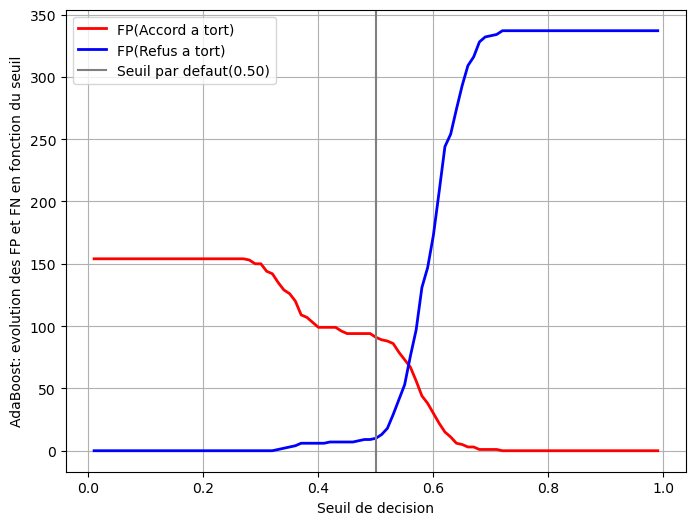

In [70]:
# graphique 1: de FP et FN pour LighGBM(le meilleur score)
plt.figure(figsize=(8,6))

data = data_seuils['AdaBoost']

plt.plot(seuils, data['fp'], label='FP(Accord a tort)', color='red', linewidth=2)
plt.plot(seuils, data['fn'], label='FP(Refus a tort)', color='blue', linewidth=2)

plt.axvline(x=0.50,color='grey', label='Seuil par defaut(0.50)')
plt.xlabel('Seuil de decision')
plt.ylabel('AdaBoost: evolution des FP et FN en fonction du seuil')
plt.legend()
plt.grid(True)
plt.show()


Pour le modele AdaBoost : le meilleur seuil compromis qui minimise les FP(Accord a tort) et limite les refus au tour de test autour s=0.56

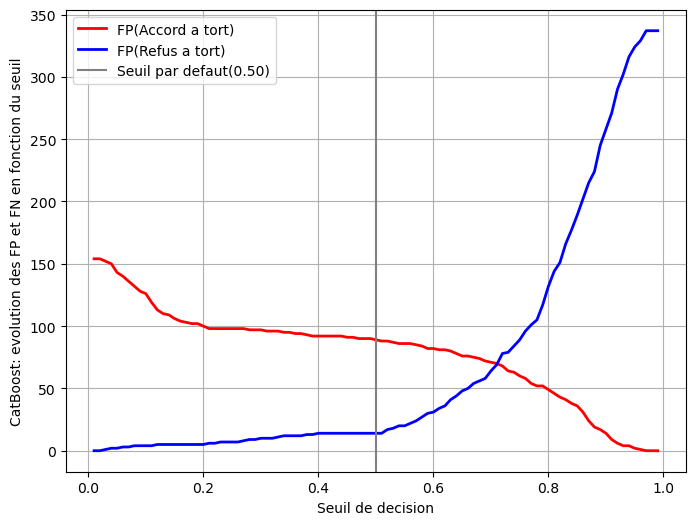

In [71]:
# graphique 1: de FP et FN pour LighGBM(le meilleur score)
plt.figure(figsize=(8,6))

data = data_seuils['CatBoost']

plt.plot(seuils, data['fp'], label='FP(Accord a tort)', color='red', linewidth=2)
plt.plot(seuils, data['fn'], label='FP(Refus a tort)', color='blue', linewidth=2)

plt.axvline(x=0.50,color='grey', label='Seuil par defaut(0.50)')
plt.xlabel('Seuil de decision')
plt.ylabel('CatBoost: evolution des FP et FN en fonction du seuil')
plt.legend()
plt.grid(True)
plt.show()


Pour le modele CatBoost : le meilleur seuil compromis qui minimise les FP(Accord a tort) et limite les refus au tour de test autour s=0.67

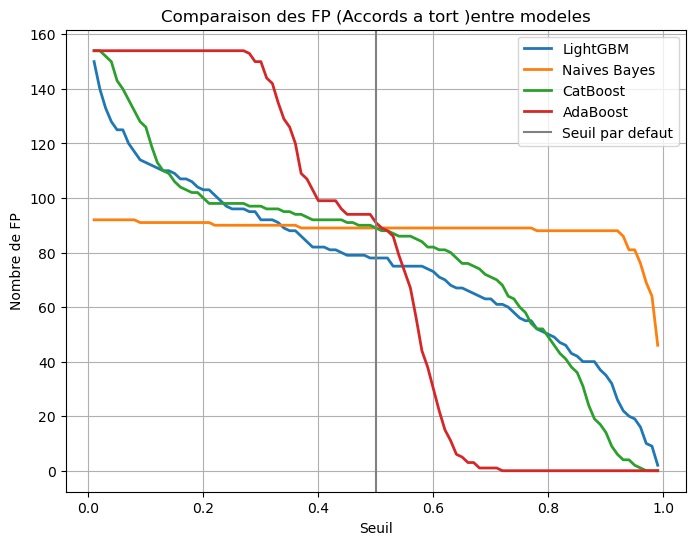

In [72]:
# graphique 2 : Comparaison des FP entre les 04 modeles

plt.figure(figsize=(8, 6))

for nom, d in data_seuils.items():
    plt.plot(seuils, d['fp'], label=nom, linewidth=2)

plt.axvline(x=0.50, color='grey', label='Seuil par defaut')
plt.xlabel('Seuil')
plt.ylabel('Nombre de FP')
plt.title('Comparaison des FP (Accords a tort )entre modeles')
plt.legend()
plt.grid(True)
plt.show()

on peut constater qu'au seuil s= 0.5 le meilleur rendement est celui de LightBoost car il a le plus petit nombre de FP=79 tandis que les autres sont autour de 90

mais si le seuil augmente il n'est plus le plus optimal uniquement sur ce point de vue. Mais a cote, on ne saurait augmenter le seuil s sans chercher le compromis entre le plus petit FP et le plus petit FN.

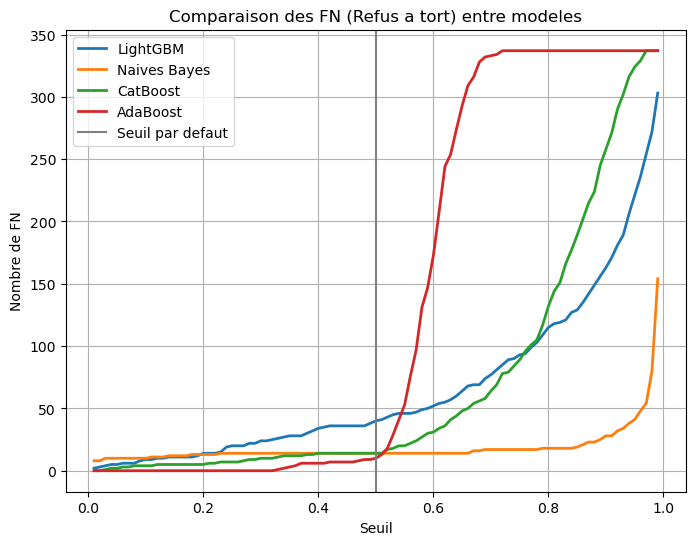

In [73]:
# Comparaison des FN (Refus a tort des )
plt.figure(figsize=(8, 6))

for nom, d in data_seuils.items():
    plt.plot(seuils, d['fn'], label=nom, linewidth=2)

plt.axvline(x=0.50, color='grey', label='Seuil par defaut')
plt.xlabel('Seuil')
plt.ylabel('Nombre de FN')
plt.title('Comparaison des FN (Refus a tort) entre modeles')
plt.legend()
plt.grid(True)
plt.show()

on peut constater qu'au seuil de s = 0.5, le meilleur modele est AdaBoost car a le plus petit FP autour de 15 contrairement aux autres qui sont plus superieur.


# e- / evaluation de chaque modele avec son seuil_optimal

In [74]:
res =[]

seuils_opt = {
    'LightGBM': 0.64,
    'Naives Bayes' : 0.98,
    'CatBoost' : 0.67,
    'AdaBoost' : 0.56
}

for nom in seuils_opt.keys():
    y_proba = predictions_oof[nom]["y_proba"]
    y_pred = (y_proba >= seuils_opt[nom]).astype(int) 

    res.append({
        'Modele': nom,
        'Precision' : precision_score(y_train, y_pred),
        'Recall' : recall_score(y_train, y_pred),
        '   f1' : f1_score(y_train, y_pred),
        'accuracy' : accuracy_score(y_train, y_pred)
    })

df_seuil = pd.DataFrame(res)
print(df_seuil.round(2).to_string(index=False)) 

      Modele  Precision  Recall     f1  accuracy
    LightGBM       0.81    0.82   0.81      0.74
Naives Bayes       0.80    0.76   0.78      0.71
    CatBoost       0.79    0.84   0.81      0.74
    AdaBoost       0.80    0.77   0.78      0.71


le meilleur modele ameliorer a partir de ces seuils d'optimisation est : LighBoost 

# f- Estimation des modeles sur les couts
contexte: Reduire les accords de credit aux non solvable(FP) 
mais a cote si possible ameliorer  les pertes econmique (FN)

nous allons estimer ces deux cout_FP et cout_FN pour chacun des modeles pour voir le meilleur
en contexte initial, nous voulons reduire les FP(credit accordé a tort) mais il semble etre inverse au manque a gagner FN (cout économique)

Nous estimons que perdre de l'argent empruntee est plus grave que perdre un client solvable. les estimations sont ci dessous:
Pour un client x, le cout est : 
- perte liquidite ===> FP : cout_FP = 30 000 FCFA
- perte de gain economique ==>  FN : 15 000 FCFA

Objectif: choisir le modele qui limite au mieux la perte globable: PG = (FP*30 000) + (FN*15 000)

In [75]:
cout_erreur =[]

# on a fixé cela a ses montants pour ne pas étendre les chiffres mais ne change rien 
cout_FP = 3000 
cout_FN = 1000

for nom in seuils_opt.keys():
    y_proba = predictions_oof[nom]["y_proba"]
    y_pred = (y_proba >= seuils_opt[nom]).astype(int) 
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()
    
    cout = (fp * cout_FP) + (fn*cout_FN)

    cout_erreur.append({
        'Modele': nom,
        'FP' : fp,
        'FN' : fn,
        'TP' : tp, 
        'TN' : tn,
        ' perte_globale' : cout
    })

df_cout_erreur = pd.DataFrame(cout_erreur)
print(df_cout_erreur.round(2).to_string(index=False)) 

    

      Modele  FP  FN  TP  TN   perte_globale
    LightGBM  67  60 277  87          261000
Naives Bayes  64  80 257  90          272000
    CatBoost  75  54 283  79          279000
    AdaBoost  67  76 261  87          277000


ce constat de perte globale montre que le modele qui minimise le plus la perte est LightBoost selon notre contexte: minimiser les FP en premier et aussi minismiser les FN.

Par contre, si notre objectif etait de reduire absolument les FN en 1er et en second les FP: le meilleur modele serait CatBoost 
car le cout_FN > cout_FP: en ce sems CatBoost serait meilleur.

# g- Gestion du desequilibre 32/68 par class_weight

In [76]:
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

In [77]:
modele_groupe_1 = {
    'LightGBM' : LGBMClassifier(class_weight='balanced', random_state=42, verbose=-1),
    'CatBoost' : CatBoostClassifier(auto_class_weights='Balanced', random_state=42, verbose=0),
}
resultat_1 = []
for name, modele in modele_groupe_1.items():
    y_pred = cross_val_predict(modele, X_train_encoded, y_train, cv=cv, method='predict', n_jobs=-1)
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()
    resultat_1.append({
        'Modele' : name,
        'FP':fp,
        'FN' : fn,
        'TP' : tp,
        "TN" : tn })
    
df_group_1 = pd.DataFrame(resultat_1)
print(df_group_1.to_string(index=False))

  Modele  FP  FN  TP  TN
LightGBM  68  56 281  86
CatBoost  78  45 292  76


In [78]:
modele_groupe_2 = {
    'AdaBoost' :AdaBoostClassifier(random_state=42),
    'Naives_Bayes' : GaussianNB()
}

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

resultat_2 = []

for nom, model in modele_groupe_2.items():
    y_pred_total = np.zeros(len(y_train))

    for train_idx, val_idx in cv.split(X_train_encoded, y_train):
        #separation des donnees
        X_train_fold = X_train_encoded.iloc[train_idx]
        X_val_fold = X_train_encoded.iloc[val_idx]
        
        y_train_fold = y_train[train_idx]
        y_val_fold = y_train[val_idx]

        fold_weights = sample_weights[train_idx]

        modele.fit(X_train_fold, y_train_fold, sample_weight=fold_weights)

        y_pred_total[val_idx] = modele.predict(X_val_fold)

    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_total).ravel()
    resultat_2.append({
        'Modele' : nom,
        'FP':fp,
        'FN' : fn,
        'TP' : tp,
        "TN" : tn
    })
df_group_2 = pd.DataFrame(resultat_2)
print(df_group_2.to_string(index=False))
    

      Modele  FP  FN  TP  TN
    AdaBoost  77  46 291  77
Naives_Bayes  77  46 291  77


Modele avec class_weight
********************************************************
Modele       FP  FN  TP  TN      ecart entre FP et FN
LightGBM     68  56 281  86      12
Naives_Bayes 77  46 291  77      31
CatBoost     78  45 292  76      33
AdaBoost     77  46 291  77      31

Modele avec seuil optimal
********************************************************
Modele       FP  FN  TP  TN   perte_globale   ecart entre FP et FN
    LightGBM  67  60 277  87          261000   7
Naives Bayes  64  80 257  90          272000   16
    CatBoost  75  54 283  79          279000   21
    AdaBoost  67  76 261  87          277000   9

# CONCLUSION FINAL 

- avec seuil_optimal : LightBoost
- avec class_weight : LightBoost
- avec estimation de l'erreur de cout : LightBoost

# 6- LightBoost : Features selection + Features enginnering + Hyperparametre
Actions a executer:

1- feature Engineering  -----> objectif: reduction des FP et FN
2- feature selection --------> objectif: reduction de bruit et amelioration de generalisation
3- hyper-parametre Tunning --------> Amelioration de la precision et du Recall

# a-/ Feature selection : 
 - correlation : eliminer les variables fortement correles
 - Mutual_Info_Classification
 - importances des variables
 - permutation importance

In [79]:
name_num_encoded = ['num__pers_en_charge', 'num__revenu_demandeur', 'num__revenu_codemmandeur', 'num__montant_pret', 'num__duree_pret']
X_train_encoded[name_num_encoded].corr()

,num__pers_en_charge,num__revenu_demandeur,num__revenu_codemmandeur,num__montant_pret,num__duree_pret
num__pers_en_charge,1.000000,0.124085,0.066088,0.139495,-0.108512
num__revenu_demandeur,0.124085,1.000000,-0.130215,0.595891,-0.046918
num__revenu_codemmandeur,0.066088,-0.130215,1.000000,0.215582,-0.100963
num__montant_pret,0.139495,0.595891,0.215582,1.000000,0.023947
num__duree_pret,-0.108512,-0.046918,-0.100963,0.023947,1.000000


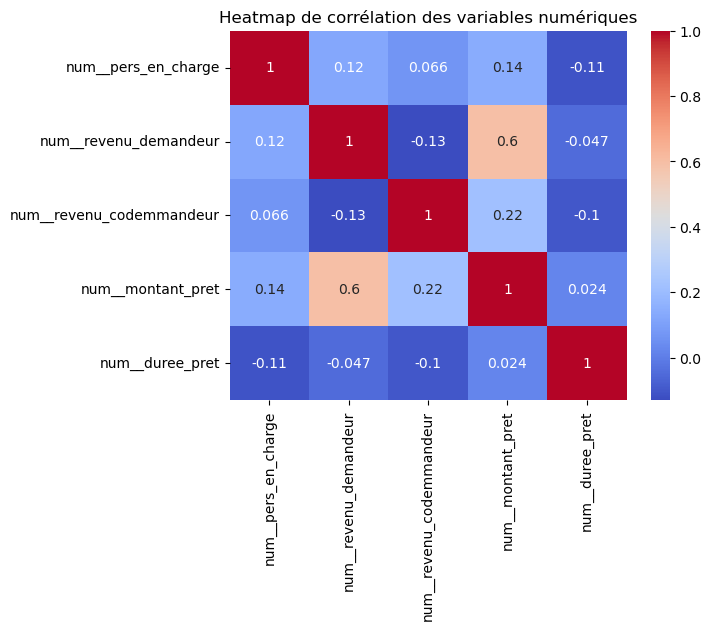

In [80]:
# Génération de la heatmap de corrélation
name_num_encoded = ['num__pers_en_charge', 'num__revenu_demandeur', 'num__revenu_codemmandeur', 'num__montant_pret', 'num__duree_pret']
sns.heatmap(X_train_encoded[name_num_encoded].corr(), cmap='coolwarm', annot=True)
plt.title('Heatmap de corrélation des variables numériques')
plt.show()

Il n'existe de forte correlation entre les variables.
la seule variable qui parait apporter une correlation au dessusde 0.5 est celle entre le revenu du codemandeur et le montant du pret.
NB: on doit verifier si ces variables apportent la meme information dans notre modele sinon elles degraderaient les performance du modele.

In [81]:
#  Mutual_Info_Classification
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X_train_encoded, y_train, random_state=42)

mi_df = pd.DataFrame({
    'feature' : list(features_names),
    'mi_score' : mi_scores,
}).sort_values(by="mi_score", ascending=False)

# affichage
print(mi_df.head().to_string(index=False))

#selection du cumul
mi_df['cumul'] = mi_df['mi_score'].cumsum() / mi_df['mi_score'].sum()
n_95_mi = (mi_df['cumul'] <= 0.95).sum()
features_mi = mi_df.head(n_95_mi)['feature'].tolist()

print(f"{n_95_mi}")

                      feature  mi_score
   cat__credit_historique_0.0  0.118439
   cat__credit_historique_1.0  0.103971
    cat__zone_residence_Urban  0.044731
     num__revenu_codemmandeur  0.035311
cat__zone_residence_Semiurban  0.033403
8


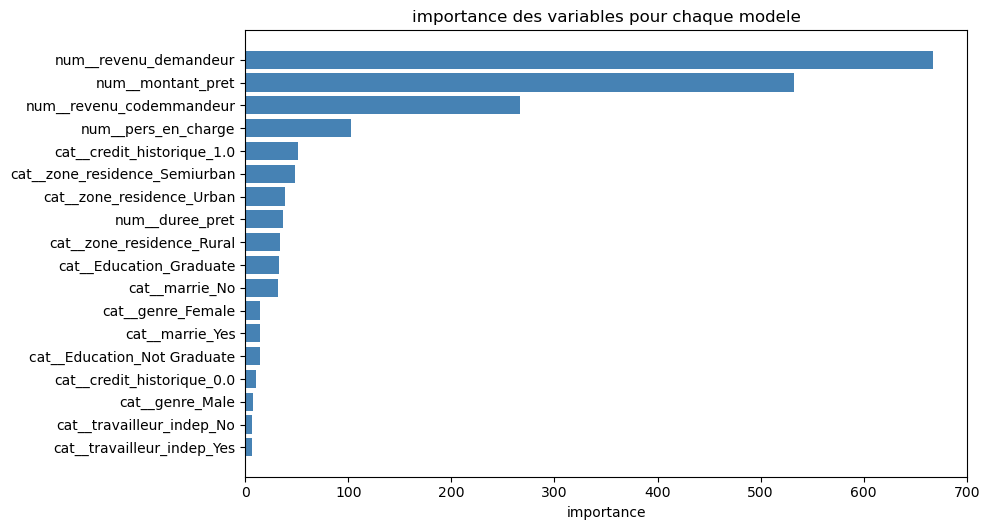


les variables conservees : 
 ['num__revenu_demandeur', 'num__montant_pret', 'num__revenu_codemmandeur', 'num__pers_en_charge', 'cat__credit_historique_1.0', 'cat__zone_residence_Semiurban', 'cat__zone_residence_Urban', 'num__duree_pret', 'cat__zone_residence_Rural', 'cat__Education_Graduate']

les variables eliminees: 
 ['cat__marrie_No', 'cat__genre_Female', 'cat__marrie_Yes', 'cat__Education_Not Graduate', 'cat__credit_historique_0.0', 'cat__genre_Male', 'cat__travailleur_indep_No', 'cat__travailleur_indep_Yes']


In [82]:
# variables par score d'importance

modele = LGBMClassifier(random_state=42, verbose=-1)
modele.fit(X_train_encoded, y_train)
scores_variabes = modele.feature_importances_

importance = pd.DataFrame({
    'variable' : features_names,
    'importance' : scores_variabes
})

# graphe de chaque variable selon son importance
importance = importance[importance['importance']>0].sort_values(by='importance', ascending=False).reset_index(drop=True)
plt.figure(figsize=(10, max(4, len(importance)*0.3)))   # hauteur s'adaptant au nbre de variable
plt.barh(importance['variable'], importance['importance'], color='steelblue')
plt.title("importance des variables pour chaque modele")
plt.xlabel('importance')
plt.gca().invert_yaxis()  # la variable la plus importante en haut
plt.tight_layout()
plt.show()


# SELECTION DES VARIABLES a 95 %
importance = importance.sort_values('importance', ascending = False)
importance['cumul'] = importance['importance'].cumsum() / importance['importance'].sum()

n_95 = (importance['cumul'] <= 0.95).sum()
features_a_conserver = importance.head(n_95)['variable'].tolist()

features_eliminees = importance.tail(len(importance) - n_95)['variable'].tolist()

print("\nles variables conservees : \n",features_a_conserver)
print("\nles variables eliminees: \n",features_eliminees)

In [83]:
# Permutation de variables
from sklearn.inspection import permutation_importance

modele = LGBMClassifier(random_state=42, verbose=-1)
modele.fit(X_train_encoded, y_train)

permut = permutation_importance(modele, X_train_encoded, y_train, random_state=42, n_repeats=10, n_jobs=-1)


perm_df = pd.DataFrame({
    'feature' : list(features_names),
    'importance' : permut.importances_mean,
    'std' : permut.importances_std,
}).sort_values(by="importance", ascending=False)

# affichage
print(perm_df.head().to_string(index=False))

#selection du cumul
perm_df['cumul'] = perm_df['importance'].cumsum() / perm_df['importance'].sum()
n_95_perm = (perm_df['cumul'] <= 0.95).sum()
features_perm = perm_df.head(n_95_perm)['feature'].tolist()

print(f"{n_95_perm}")


                   feature  importance      std
     num__revenu_demandeur    0.169043 0.016319
         num__montant_pret    0.141752 0.009561
cat__credit_historique_1.0    0.126680 0.008535
  num__revenu_codemmandeur    0.074542 0.007411
       num__pers_en_charge    0.034420 0.006721
9


In [85]:
# intersection des variables qui reviennent
ens_lightgbm = set(features_a_conserver)
ens_mi = set(features_mi)
ens_perm = set(features_perm)

intersection = ens_lightgbm & ens_mi & ens_perm

print("\nles variables communes aux 03 methodes:\n", intersection)



les variables communes aux 03 methodes:
 {'num__revenu_codemmandeur', 'cat__credit_historique_1.0', 'cat__zone_residence_Semiurban'}


-

ensemble lightgbm                           Mutual Info                            permutation Importance

-------------------------------------------------------------------------------------------------------------------
{'cat__Education_Graduate',                'cat__Education_Not Graduate',
 ----------------------------------------------------------------------------------------------------------------------------------
 'cat__credit_historique_1.0',              'cat__credit_historique_1.0',         'cat__credit_historique_1.0',
 ---------------------------------------------------------------------------------------------------------------------------------
 'cat__zone_residence_Rural',                                                      'cat__zone_residence_Rural',
 --------------------------------------------------------------------------------------------------------------------------
 'cat__zone_residence_Semiurban',           'cat__zone_residence_Semiurban',        'cat__zone_residence_Semiurban',
 ----------------------------------------------------------------------------------------------------------------------------------
 'cat__zone_residence_Urban',                'cat__zone_residence_Urban',
 -----------------------------------------------------------------------------------------------------------------------------------
 'num__duree_pret',                                                                'num__duree_pret',
 ----------------------------------------------------------------------------------------------------------------------------------
 'num__montant_pret',                                                              'num__montant_pret',
 --------------------------------------------------------------------------------------------------------------------------------
  'num__pers_en_charge',                                                            'num__pers_en_charge',
 ---------------------------------------------------------------------------------------------------------------------------------
 'num__revenu_codemmandeur',                'num__revenu_codemmandeur'}             'num__revenu_codemmandeur',
 ----------------------------------------------------------------------------------------------------------------------------------
 'num__revenu_demandeur'}                                                           'num__revenu_demandeur'}
 ----------------------------------------------------------------------------------------------------------------------------------
                                                                                    'cat__marrie_No',
                                                                                    'cat__marrie_No',

                                            'cat__credit_historique_0.0',
                                            'cat__marrie_Yes',
                                            'cat__travailleur_indep_Yes',
 
 
on conclut que pour les trois methodes evaluées, certaines variables reviennent 03 fois, d'autres 02 fois et d'autres uniquement 01 fois
Nous conserverons les variables qui reviennent 02 ou 03 fois et celles aui sont 01 fois seront ecartées.
En observant cela revient encore a garder toutes les variables de la feature Importance integree a la methode LightGBM

In [86]:
# variables garder : Evaluer a nouveau notre modele sur ces variables 

variables_final_conservees = features_a_conserver
variables_final_conservees

['num__revenu_demandeur',
 'num__montant_pret',
 'num__revenu_codemmandeur',
 'num__pers_en_charge',
 'cat__credit_historique_1.0',
 'cat__zone_residence_Semiurban',
 'cat__zone_residence_Urban',
 'num__duree_pret',
 'cat__zone_residence_Rural',
 'cat__Education_Graduate']

In [87]:
# Comparaison des deux variables brutes avec feature selection donc nos 10 variables

# modele avec toutes les variables 
seuil = 0.64
modele_all = LGBMClassifier( random_state=42, verbose=-1)
modele_all.fit(X_train_encoded, y_train)
y_proba_cv_all = cross_val_predict(modele_all, X_train_encoded, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1] # recupere les probab de la classe 1
y_pred_cv_all = (y_proba_cv_all <= seuil).astype(int)                                                          # recupere les valeurs inf.ou egale au seuil et transforme en 0 ou 1
tn_all, fp_all, fn_all, tp_all = confusion_matrix(y_train, y_pred_cv_all).ravel()

# modele issu de features slection fs 
X_train_fs = X_train_encoded[variables_final_conservees]
modele_fs = LGBMClassifier(random_state=42, verbose=-1)
modele_fs.fit(X_train_encoded, y_train)
y_proba_cv_fs= cross_val_predict(modele_fs, X_train_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1]
y_pred_cv_fs = (y_proba_cv_fs <= seuil).astype(int)
tn_fs, fp_fs, fn_fs, tp_fs = confusion_matrix(y_train, y_pred_cv_fs).ravel()

# Tableau comparatif
comparaison = pd.DataFrame({
    'version' : ['Toutes variables', 'selection(95)'],
    'TP' :[tp_all, tp_fs],
    'TN': [tn_all, tn_fs],
    'FP' : [fp_all, fp_fs],
    'FN' : [fn_all, fn_fs],
})
print(comparaison.to_string(index=False))

         version  TP  TN  FP  FN
Toutes variables  60  67  87 277
   selection(95)  61  68  86 276


In [88]:
# nous avons retiré la variable revenu_codemandeur pour evaluer entre la performance pour voir si elle s' ameliore
var_9 = ['num__revenu_demandeur',
        'num__montant_pret',
        'num__pers_en_charge',
        'cat__credit_historique_1.0',
        'cat__zone_residence_Semiurban',
        'cat__zone_residence_Urban',
        'num__duree_pret',
        'cat__zone_residence_Rural',
        'cat__Education_Graduate']

In [89]:
# Comparaison des deux variables brutes avec feature selection maintenant a 9 variables 
seuil = 0.64
modele_all = LGBMClassifier( random_state=42, verbose=-1)
modele_all.fit(X_train_encoded, y_train)
y_proba_cv_all = cross_val_predict(modele_all, X_train_encoded, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1] # recupere les probab de la classe 1
y_pred_cv_all = (y_proba_cv_all <= seuil).astype(int)                                                          # recupere les valeurs inf.ou egale au seuil et transforme en 0 ou 1
tn_all, fp_all, fn_all, tp_all = confusion_matrix(y_train, y_pred_cv_all).ravel()

# modele issu de features slection fs
X_train_fs = X_train_encoded[var_9]
modele_fs = LGBMClassifier(random_state=42, verbose=-1)
modele_fs.fit(X_train_encoded, y_train)
y_proba_cv_fs= cross_val_predict(modele_fs, X_train_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1]
y_pred_cv_fs = (y_proba_cv_fs <= seuil).astype(int)
tn_fs, fp_fs, fn_fs, tp_fs = confusion_matrix(y_train, y_pred_cv_fs).ravel()

# Tableau comparatif
comparaison = pd.DataFrame({
    'version' : ['Toutes variables', 'selection(95)'],
    'TP' :[tp_all, tp_fs],
    'TN': [tn_all, tn_fs],
    'FP' : [fp_all, fp_fs],
    'FN' : [fn_all, fn_fs],
})
print(comparaison.to_string(index=False))

         version  TP  TN  FP  FN
Toutes variables  60  67  87 277
   selection(95)  67  68  86 270


# b-/ features engineering

Nous allons ajouter de nouvelles variables au dataset apres feature_selection et réevaluer le modèle.

ces nouvelles variables a creer et leur significations:

- ratio_endettement = montant_pret / revenu_demandeur  ===> capacite a rembourser
- ratio_endettement_foyer = montant_pret / (revenu co_demandeur + revenu_demandeur)
- pers_en_charge / revenu_demandeur (charge familiale par rapport au revenu)
- ratio endettement par charge du demandeur =  num__montant_pret / num__pers_en_charge + 1
- duree en annees = pret_annee = num__duree_pret / 365
- risk_endettement = num__montant_pret / (num__revenu_demandeur* 0.33)
- montant_si_historique = num__montant_pret * cat__credit_historique_1.0

In [90]:
X_train_fe = X_train_encoded.copy()

In [91]:
# creation de nouvelles variables 

# capacite endettement
X_train_fe['ratio_endettement'] = X_train_fe['num__montant_pret']/ X_train_fe['num__revenu_demandeur']

# ratio endettement menage
X_train_fe['ratio_endettement_menage'] = X_train_fe['num__montant_pret']  / (X_train_fe['num__revenu_demandeur'] + X_train_fe['num__revenu_codemmandeur'])

#ratio endettement par charge du demandeur
X_train_fe['ratio_charge_revenu'] =  X_train_fe['num__montant_pret'] / X_train_fe['num__pers_en_charge'] + 1

# duree en annees
X_train_fe['pret_annee'] = X_train_fe['num__duree_pret'] /365 

# Risque d'endettement: seuil banque = 33%--- si >1 le client depasse le seuil d'endettement
X_train_fe['risk_endettement'] = X_train_fe['num__montant_pret'] / (X_train_fe['num__revenu_demandeur'] * 0.33)

# es ce un montant elevee est plus risque si on un historique ?
X_train_fe['montant_si_historique'] = X_train_fe['num__montant_pret'] * X_train_fe['cat__credit_historique_1.0'] 

In [92]:
name_var_fe = ['num__revenu_demandeur', 'num__montant_pret', 'num__pers_en_charge', 'cat__credit_historique_1.0', 
               'cat__zone_residence_Semiurban','cat__zone_residence_Urban','num__duree_pret','cat__zone_residence_Rural',
               'cat__Education_Graduate', 'ratio_endettement', 'ratio_endettement_menage', 'ratio_charge_revenu',
               'pret_annee', 'risk_endettement', 'montant_si_historique']

In [93]:
X_train_featur_eng = X_train_fe[name_var_fe]
X_train_featur_eng.head(1)

,num__revenu_demandeur,num__montant_pret,num__pers_en_charge,cat__credit_historique_1.0,cat__zone_residence_Semiurban,cat__zone_residence_Urban,...,ratio_endettement,ratio_endettement_menage,ratio_charge_revenu,pret_annee,risk_endettement,montant_si_historique
154,-0.207263,-1.209302,0.0,1.0,0.0,1.0,...,5.834634,1.810952,-inf,0.0,17.680709,-1.209302


In [94]:
# Comparaison des deux variables brutes avec feature selection maintenant a 9 variables 

seuil = 0.64

# modele issu de features slection fs
X_train_fs = X_train_encoded[var_9]
modele_fs = LGBMClassifier(random_state=42, verbose=-1)
modele_fs.fit(X_train_encoded, y_train)
y_proba_cv_fs= cross_val_predict(modele_fs, X_train_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1]
y_pred_cv_fs = (y_proba_cv_fs <= seuil).astype(int)
tn_fs, fp_fs, fn_fs, tp_fs = confusion_matrix(y_train, y_pred_cv_fs).ravel()

# MODELE Engineering
modele_fe = LGBMClassifier( random_state=42, verbose=-1)
modele_fe.fit(X_train_featur_eng, y_train)
y_proba_cv_fe = cross_val_predict(modele_fe, X_train_featur_eng, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1] # recupere les probab de la classe 1
y_pred_cv_fe = (y_proba_cv_fe <= seuil).astype(int)                                                          # recupere les valeurs inf.ou egale au seuil et transforme en 0 ou 1
tn_fe, fp_fe, fn_fe, tp_fe = confusion_matrix(y_train, y_pred_cv_fe).ravel()


# Tableau comparatif entre feature selection(Baseline) et nouvelles features(features engineering)
comparaison_fe = pd.DataFrame({
    'version' : ['features selection(95%):', 'features_engineering:'],
    'TP' :[tp_fs, tp_fe],
    'TN': [tn_fs, tn_fe],
    'FP' : [fp_fs,fp_fe],
    'FN' : [fn_fs, fn_fe],
})
print(comparaison_fe.to_string(index=False))

                 version  TP  TN  FP  FN
features selection(95%):  67  68  86 270
   features_engineering:  59  74  80 278


on observe en comparant features_engineering a features selection(95%) :
- TP: diminue de 8 points : pas bon
- TN : augmente de 6 points: pas bon
- FP : augmente de 6 points : bon
- FN : diminue de 8 points : pas bon
conclusion: toutes les variables de la feature enginnering ajoute du bruit et n ameliore pas le modele en plus

le modele de feature selection a 9 variables est meilleur que le modele d'ajout de variable(features engineering)

nous allons chercher precisement de ces variables de features engineering, celles qui degradent la performance en :
- faisant de la permutation importance sur le df_engineering
- eliminer les variables causant le bruit et tester pour voir si la performance a evoluee

In [95]:
# Nom deS nouvelles variables pour les cibler dans X_train_featur_eng

var_engine_ajout = [
    'ratio_endettement',
    'ratio_endettement_menage',
    'ratio_charge_revenu',
    'pret_annee',
    'risk_endettement',
    'montant_si_historique']

In [96]:
# Recherche du bruit dans les nouvelles variables par permutations variables 

modele = LGBMClassifier(random_state=42, verbose=-1)
modele.fit(X_train_featur_eng, y_train)

permut_eng = permutation_importance(modele, X_train_featur_eng, y_train, random_state=42, n_repeats=10, n_jobs=-1)


perm_df_eng = pd.DataFrame({
    'feature' : list(X_train_featur_eng.columns),
    'importance' : permut_eng.importances_mean,
    'std' : permut_eng.importances_std,
}).sort_values(by="importance", ascending=False)

# affichage
print(perm_df_eng.head().to_string(index=False))

#selection du cumul
perm_df_eng['cumul'] = perm_df_eng['importance'].cumsum() / perm_df_eng['importance'].sum()
n_95_perm_eng = (perm_df_eng['cumul'] <= 0.95).sum()
features_perm_eng = perm_df_eng.head(n_95_perm_eng)['feature'].tolist()

print(f"{n_95_perm_eng}")


                   feature  importance      std
cat__credit_historique_1.0    0.183707 0.010922
     num__revenu_demandeur    0.129532 0.008208
  ratio_endettement_menage    0.099389 0.008238
         ratio_endettement    0.096130 0.009190
         num__montant_pret    0.070468 0.004387
8


In [97]:
# Nom des  variables issu du resultat de permutation_importance pour les cibler dans X_train_featur_eng

cible_var5 = ['cat__credit_historique_1.0', 'num__revenu_demandeur', 
              'ratio_endettement_menage', 'ratio_endettement', 'num__montant_pret']

In [98]:
# nouveau X_train de feature selection basé uniquement sur les 05 variables issus du resultat de importance_permutation
X_train_5f_fs = X_train_featur_eng[cible_var5]

In [99]:
# Comparaison des deux variables brutes avec feature selection maintenant a 9 variables 

seuil = 0.64

# modele issu de features slection fs
X_train_fs = X_train_encoded[var_9]
modele_fs = LGBMClassifier(random_state=42, verbose=-1)
modele_fs.fit(X_train_encoded, y_train)
y_proba_cv_fs= cross_val_predict(modele_fs, X_train_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1]
y_pred_cv_fs = (y_proba_cv_fs <= seuil).astype(int)
tn_fs, fp_fs, fn_fs, tp_fs = confusion_matrix(y_train, y_pred_cv_fs).ravel()

# MODELE Engineering
modele_fe = LGBMClassifier( random_state=42, verbose=-1)
modele_fe.fit(X_train_5f_fs, y_train)
y_proba_cv_fe = cross_val_predict(modele_fe, X_train_5f_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1] # recupere les probab de la classe 1
y_pred_cv_fe = (y_proba_cv_fe <= seuil).astype(int)                                                          # recupere les valeurs inf.ou egale au seuil et transforme en 0 ou 1
tn_fe, fp_fe, fn_fe, tp_fe = confusion_matrix(y_train, y_pred_cv_fe).ravel()


# Tableau comparatif entre feature selection(Baseline) et nouvelles features(features engineering)
comparaison_fe = pd.DataFrame({
    'version' : ['features selection(95%):', 'features_engineering:'],
    'TP' :[tp_fs, tp_fe],
    'TN': [tn_fs, tn_fe],
    'FP' : [fp_fs,fp_fe],
    'FN' : [fn_fs, fn_fe],
})
print(comparaison_fe.to_string(index=False))

                 version  TP  TN  FP  FN
features selection(95%):  67  68  86 270
   features_engineering:  64  72  82 273


In [ ]:
# Nous avons observer que 02 variables etaient nouvelles lors de la permiutation du X_train_fe. 
# on va garder ces deux variables que nous allons ajouter au X_train_fe

In [100]:
name_var_fe_11 = ['num__revenu_demandeur', 'num__montant_pret', 'num__pers_en_charge', 'cat__credit_historique_1.0', 
               'cat__zone_residence_Semiurban','cat__zone_residence_Urban','num__duree_pret','cat__zone_residence_Rural',
               'cat__Education_Graduate', 'ratio_endettement', 'ratio_endettement_menage']

In [101]:
X_train_featur_eng2 = X_train_featur_eng[name_var_fe_11]

In [102]:
# Comparaison des deux variables brutes avec feature selection maintenant a 9 variables 

seuil = 0.64

# modele issu de features slection fs
X_train_fs = X_train_encoded[var_9]
modele_fs = LGBMClassifier(random_state=42, verbose=-1)
modele_fs.fit(X_train_encoded, y_train)
y_proba_cv_fs= cross_val_predict(modele_fs, X_train_fs, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1]
y_pred_cv_fs = (y_proba_cv_fs <= seuil).astype(int)
tn_fs, fp_fs, fn_fs, tp_fs = confusion_matrix(y_train, y_pred_cv_fs).ravel()

# MODELE Engineering
modele_fe = LGBMClassifier( random_state=42, verbose=-1)
modele_fe.fit(X_train_featur_eng2, y_train)
y_proba_cv_fe = cross_val_predict(modele_fe, X_train_featur_eng2, y_train, cv=cv,  method='predict_proba', n_jobs=-1)[:,1] # recupere les probab de la classe 1
y_pred_cv_fe = (y_proba_cv_fe <= seuil).astype(int)                                                          # recupere les valeurs inf.ou egale au seuil et transforme en 0 ou 1
tn_fe, fp_fe, fn_fe, tp_fe = confusion_matrix(y_train, y_pred_cv_fe).ravel()


# Tableau comparatif entre feature selection(Baseline) et nouvelles features(features engineering)
comparaison_fe = pd.DataFrame({
    'version' : ['features selection(95%):', 'features_engineering2:'],
    'TP' :[tp_fs, tp_fe],
    'TN': [tn_fs, tn_fe],
    'FP' : [fp_fs,fp_fe],
    'FN' : [fn_fs, fn_fe],
})
print(comparaison_fe.to_string(index=False))

                 version  TP  TN  FP  FN
features selection(95%):  67  68  86 270
  features_engineering2:  67  75  79 270


Nous obervons des resultats interessants en comparant feature_engineering2 a features_selection a 9 variables:
- TP: pas d'augmentation : stable
- TN : augmentation de 7 points : tres bon
- FP : diminution de 7 points : tres bon
- FN : pas d'augmentation : stable
Conclusion: les nouvelles variables que nous avons ajoutees lors de cette feature enginneering a augmenter la performance du modele

In [103]:
X_train_featur_eng2.shape

(491, 11)

In [104]:
X_test_encoded.shape

(123, 18)

# h-/ hyper-parametrisation

on va rechercher les parametres optimaux qui donneraient une performance optimale du modele.
pour commencer:
- on applique un ensemble de paramètre pour que le modèle definissent les paramètres optimaux
- on reevalue la performance
- on verifie l'overfitting/underfitting
- on ajuste continuellement pour limiter l'overfitting/underfitting si cela existe.

Des que tout est correcte, on finalise notre travail en utilisant notre 20% df_test

In [105]:
# 1er parametrage

from sklearn.model_selection import GridSearchCV

param_grid ={
    'max_depth' : [3, 5, 7, 9],        # profondeur de l'arbre
    "num_leaves" : [20, 31, 50, 70],   # nombre de feuilles max
    "learning_rate" : [0.01, 0.05, 0.1], # taux d'apprentissage
    "n_estimators" : [100, 150, 200],     # nombres d'arbres
    "min_child_samples" : [10, 20, 30]   # echantillon min par feuilles
}

modele_base = LGBMClassifier(random_state=42, verbose=-1)

grid_search = GridSearchCV(estimator=modele_base, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train_featur_eng2, y_train)

for param, valeur in grid_search.best_params_.items():
    print(f" {param} : {valeur} ")
    
print(f"Meilleur score(ROC-AUC moyen en CV) {grid_search.best_score_}")
meilleur_modele = grid_search.best_estimator_


 learning_rate : 0.1 
 max_depth : 7 
 min_child_samples : 30 
 n_estimators : 150 
 num_leaves : 20 
Meilleur score(ROC-AUC moyen en CV) 0.7683076552720269


In [106]:
# 1er parametrage

from sklearn.model_selection import GridSearchCV

param_grid ={
    'max_depth' : [5, 7, 9, 11],        # profondeur de l'arbre
    "num_leaves" : [30, 50, 70, 90],   # nombre de feuilles max
    "learning_rate" : [0.01, 0.05, 0.1], # taux d'apprentissage
    "n_estimators" : [150, 250, 400],     # nombres d'arbres
    "min_child_samples" : [10, 20, 30]   # echantillon min par feuilles
}

modele_base = LGBMClassifier(random_state=42, verbose=-1)

grid_search = GridSearchCV(estimator=modele_base, param_grid=param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)

grid_search.fit(X_train_featur_eng2, y_train)

for param, valeur in grid_search.best_params_.items():
    print(f" {param} : {valeur} ")
    
print(f"Meilleur score(ROC-AUC moyen en CV) {grid_search.best_score_}")
meilleur_modele = grid_search.best_estimator_


 learning_rate : 0.1 
 max_depth : 7 
 min_child_samples : 30 
 n_estimators : 150 
 num_leaves : 30 
Meilleur score(ROC-AUC moyen en CV) 0.7683076552720269


In [107]:
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score, roc_auc_score

In [108]:
# evaluation final sur le df_train: donnees d'entrainement
params_finaux = {
    'learning_rate' : 0.1, 
 'max_depth' : 7,
 'min_child_samples' : 30, 
 'n_estimators' : 150 ,
 'num_leaves' : 30 ,
    "random_state" :42,
    'verbose': -1,
}

modele_final = LGBMClassifier(**params_finaux)

# prediction en cv
y_proba_final = cross_val_predict(modele_final, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]

# application au seuil
seuil = 0.64
y_pred_final = (y_proba_final >= seuil).astype(int)

# matrice de confusion
tn_f, fp_f, fn_f,tp_f = confusion_matrix(y_train, y_pred_final).ravel()

print("**********Performance du modele final sur X_train avec CV *************")
print(f"TP(Bon accord): {tp_f}")
print(f"TN(Bon refus): {tn_f}")
print(f"FP(Accord a tort): {fp_f}")
print(f"FN(Refus a tort): {fn_f}")

print("**********Classification Report du modele final sur X_train avec CV *************")
print(classification_report(y_train, y_pred_final, target_names=['Refus(0)' , 'Accord(1)']))

# metriques 
accuracy = accuracy_score(y_train, y_pred_final)
roc_auc = roc_auc_score(y_train, y_pred_final)
precision = precision_score(y_train, y_pred_final)
recall = recall_score(y_train, y_pred_final)
f1 = f1_score(y_train, y_pred_final)

# affichage des metriques 
print(f"accuracy: {accuracy:.4f}")
print(f"roc_auc : {roc_auc:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"f1_score: {f1:.4f}")


**********Performance du modele final sur X_train avec CV *************
TP(Bon accord): 280
TN(Bon refus): 85
FP(Accord a tort): 69
FN(Refus a tort): 57
**********Classification Report du modele final sur X_train avec CV *************
              precision    recall  f1-score   support

    Refus(0)       0.60      0.55      0.57       154
   Accord(1)       0.80      0.83      0.82       337

    accuracy                           0.74       491
   macro avg       0.70      0.69      0.70       491
weighted avg       0.74      0.74      0.74       491

accuracy: 0.7434
roc_auc : 0.6914
precision: 0.8023
recall: 0.8309
f1_score: 0.8163


ces resultats montrent une bonne amelioration et un equilibre dans notre modele.

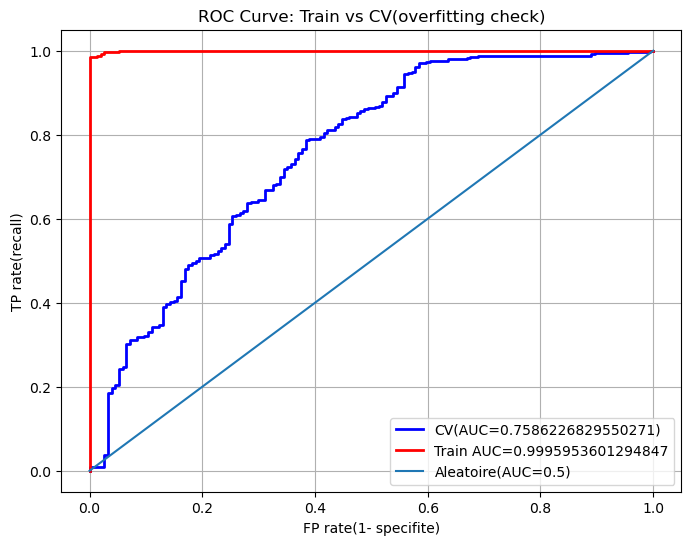

Ecart entre AUC_train et AUC_CV : 0.24


In [109]:
# Regulation de l' Overfitting  sur X_train : dimuninuer la complexite et avoir des regles simples , d'ou reduire les regles specifiques
# il faut que l'ecart entre le train AUC et le CV AUC soit compris entre [0.01 - 0.05[

modele_over_under = LGBMClassifier(
    num_leaves=30,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [20-70]
    max_depth=7,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    #reg_alpha =               # penalise les poids importants(l1/LASSO): augmenter reduit Overfitt / souvent compris[0 - 5]
    #reg_lambda =              # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 5]
    #feature_fraction = 0.8,   # Nbre variables a utiliser: si 100 ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.1,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=150,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    random_state=42,
    verbose=-1
)



# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)
auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

constat:
overfitting severe car Train AUC - CV AUC  = 0.99 - 0.75 = 0.24 > +/- 0.02: le modele a trop de complexite (hyper_parametres)
et n'arrive pas a bien generaliser sur de nouvelles donnees.

but: regler les hyperparametres de maniere a ce que la courbe Train rejoind la courbe AUC (CV)

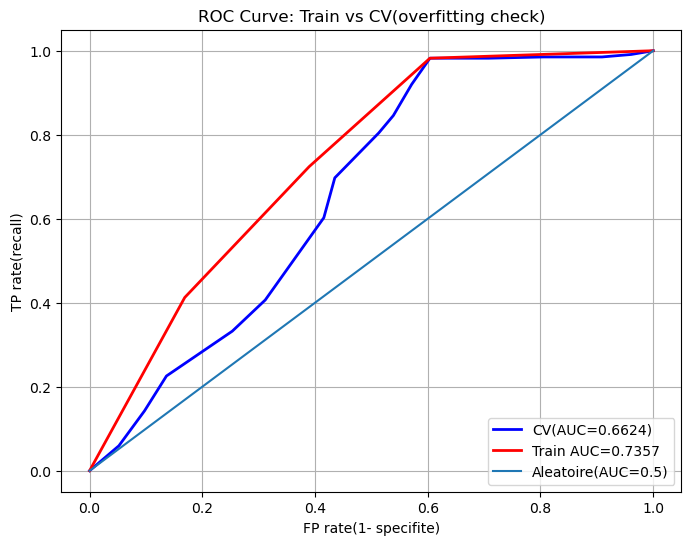

Ecart entre AUC_train et AUC_CV : 0.07


In [110]:
# 1er Parametrage

modele_over_under = LGBMClassifier(
    num_leaves = 30,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [20-70]
    max_depth=4,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    reg_alpha = 10,              # penalise les poids importants(l1/LASSO): si on augmente, reduit Overfitt / souvent compris[0 - 5]
    reg_lambda =1,            # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 5]
    #feature_fraction = 1,   # Nbre variables a utiliser: si 100% ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.1,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=150,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    random_state=42,
    verbose=-1
)



# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)
auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc:.4f})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train:.4f}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

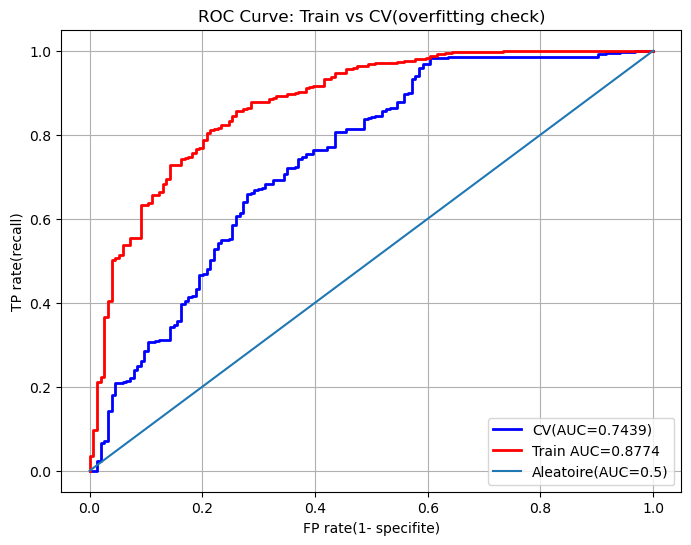

Ecart entre AUC_train et AUC_CV : 0.13


In [111]:
# 2 eme Parametrage

modele_over_under = LGBMClassifier(
    num_leaves = 12,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [20-70]
    max_depth=4,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    reg_alpha = 3,              # penalise les poids importants(l1/LASSO): si on augmente, reduit Overfitt / souvent compris[0 - 10]
    reg_lambda =1,            # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 10]
    feature_fraction = 1,   # Nbre variables a utiliser: si 100% ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.01,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=500,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)
auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc:.4f})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train:.4f}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

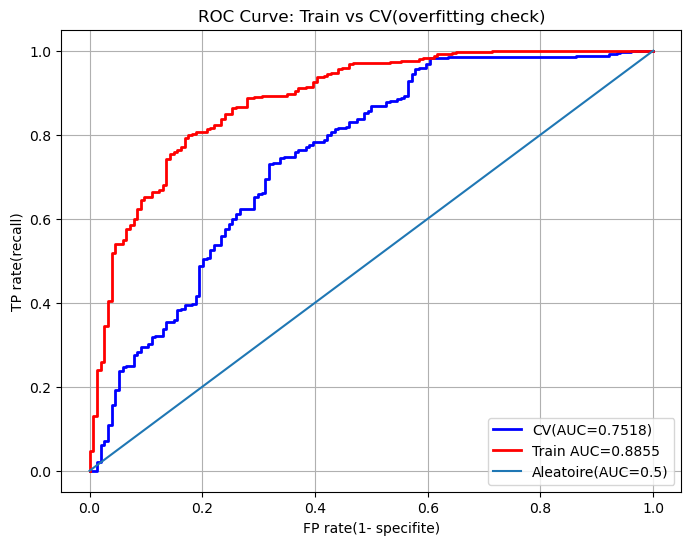

Ecart entre AUC_train et AUC_CV : 0.13


In [112]:
# 3 eme Parametrage

modele_over_under = LGBMClassifier(
    num_leaves = 20,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [10-70]
    max_depth=4,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    reg_alpha = 2,              # penalise les poids importants(l1/LASSO): si on augmente, reduit Overfitt / souvent compris[0 - 10]
    reg_lambda =1,            # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 10]
    feature_fraction = 0.8,   # Nbre variables a utiliser: si 100% ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.01,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=500,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)

auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc:.4f})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train:.4f}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

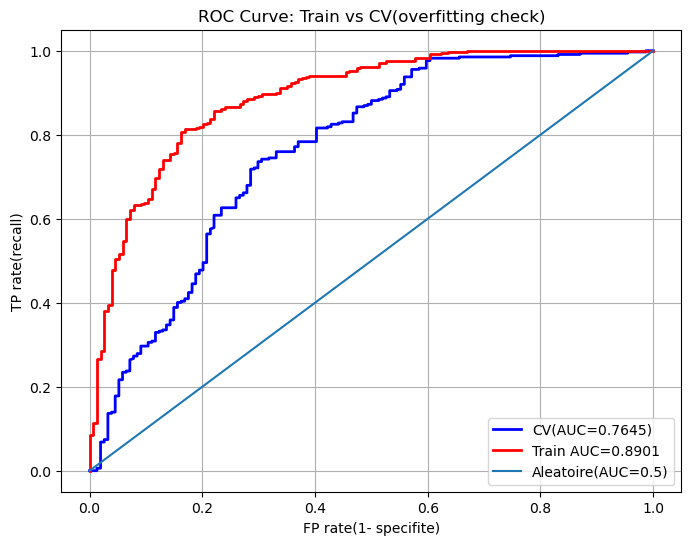

Ecart entre AUC_train et AUC_CV : 0.13


In [113]:
# 4 eme Parametrage

modele_over_under = LGBMClassifier(
    num_leaves = 20,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [10-70]
    max_depth=4,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    reg_alpha = 2,              # penalise les poids importants(l1/LASSO): si on augmente, reduit Overfitt / souvent compris[0 - 10]
    reg_lambda =1,            # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 10]
    feature_fraction = 0.8,   # Nbre variables a utiliser: si 100% ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.05,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=150,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)

auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc:.4f})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train:.4f}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

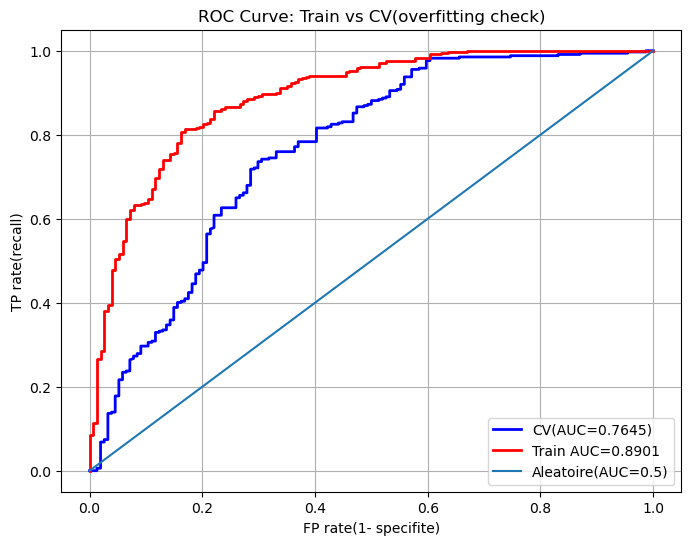

Ecart entre AUC_train et AUC_CV : 0.13


In [114]:
# 5 eme parametrage : modele avec hyper parametres retenues

modele_over_under = LGBMClassifier(
    num_leaves = 15,           #  trop grand = complexite ----> a reduire compris []  /  souvent compris [10-70]
    max_depth=4,             # profondeur des arbres: si grand=complexite   -------> A reduire : compris entre [3-4] / tres bas = underfitting(modele trop simple)
    min_child_samples= 30,    # Nbre de feuilles d'observation: si petite = complexite -----> A augmenter : compris entre [10 - 50]
    reg_alpha = 2,              # penalise les poids importants(l1/LASSO): si on augmente, reduit Overfitt / souvent compris[0 - 10]
    reg_lambda =1,            # penalise les poids eleves (Ridge) : valeur elevee reduit les poids donc overfitt / souvent compris [0.5 - 10]
    feature_fraction = 0.8,   # Nbre variables a utiliser: si 100% ou 1: tres dependant des variables or 0.8 =modele diversifiee
    learning_rate=0.05,       # en lien avec n_estimators: si learning_rate baisse + n_estimators doit augmenter. / souventcompris [0.01-0.2]
    n_estimators=150,       # monte ou baisse en fonction du learning rate  / [100 - 500]
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

# prediction en cv
y_proba1 = cross_val_predict(modele_over_under, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]
modele_over_under.fit(X_train_featur_eng2, y_train)
y_proba_train = modele_over_under.predict_proba(X_train_featur_eng2)[:,1]

# ROC
fpr, tpr,_ = roc_curve(y_train, y_proba1)
fpr_train, tpr_train,_ = roc_curve(y_train, y_proba_train)

auc = roc_auc_score(y_train, y_proba1)
auc_train = roc_auc_score (y_train, y_proba_train)

# affichage des metriques 
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"CV(AUC={auc:.4f})", color='blue', linewidth=2)
plt.plot(fpr_train, tpr_train, label=f"Train AUC={auc_train:.4f}", color='red', linewidth=2)
plt.plot([0, 1], [0, 1], label='Aleatoire(AUC=0.5)')

plt.xlabel('FP rate(1- specifite)')
plt.ylabel('TP rate(recall)')
plt.title('ROC Curve: Train vs CV(overfitting check)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print("Ecart entre AUC_train et AUC_CV :", round(auc_train-auc, 2))

In [115]:
# evaluationfinal sur le df_train: donnees d'entrainement avec le dernier parametrage

modele_final = LGBMClassifier(
    num_leaves = 15,           
    max_depth=4,            
    min_child_samples= 30,   
    reg_alpha = 2,             
    reg_lambda =1,           
    feature_fraction = 0.8,   
    learning_rate=0.05,       
    n_estimators=150,       
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

# prediction en cv
y_proba_final = cross_val_predict(modele_final, X_train_featur_eng2, y_train, cv=cv, method='predict_proba')[:,1]

# application au seuil
seuil = 0.64
y_pred_final = (y_proba_final >= seuil).astype(int)

# matrice de confusion
tn_f, fp_f, fn_f,tp_f = confusion_matrix(y_train, y_pred_final).ravel()

print("**********Performance du modele final sur X_train avec CV *************")
print(f"TP(Bon accord): {tp_f}")
print(f"TN(Bon refus): {tn_f}")
print(f"FP(Accord a tort): {fp_f}")
print(f"FN(Refus a tort): {fn_f}")

print("**********Classification Report du modele final sur X_train avec CV *************")
print(classification_report(y_train, y_pred_final, target_names=['Refus(0)' , 'Accord(1)']))

# metriques 
accuracy = accuracy_score(y_train, y_pred_final)
roc_auc = roc_auc_score(y_train, y_pred_final)
precision = precision_score(y_train, y_pred_final)
recall = recall_score(y_train, y_pred_final)
f1 = f1_score(y_train, y_pred_final)

# affichage des metriques 
print(f"accuracy: {accuracy:.4f}")
print(f"roc_auc : {roc_auc:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"f1_score: {f1:.4f}")


**********Performance du modele final sur X_train avec CV *************
TP(Bon accord): 299
TN(Bon refus): 74
FP(Accord a tort): 80
FN(Refus a tort): 38
**********Classification Report du modele final sur X_train avec CV *************
              precision    recall  f1-score   support

    Refus(0)       0.66      0.48      0.56       154
   Accord(1)       0.79      0.89      0.84       337

    accuracy                           0.76       491
   macro avg       0.72      0.68      0.70       491
weighted avg       0.75      0.76      0.75       491

accuracy: 0.7597
roc_auc : 0.6839
precision: 0.7889
recall: 0.8872
f1_score: 0.8352


Baseline_Hyperparametre       Model apres ajustement Overfitting

accuracy:  0.7597              0.7434
roc_auc :  0.6839              0.6914
precision: 0.7889              0.8023
recall:    0.8872              0.8309
f1_score:  0.8352              0.8163
-------------------------------------------------
TP(Bon accord):    299         280
TN(Bon refus):     74          85
FP(Accord a tort): 80          69
FN(Refus a tort):  38          57

le tunning de l'overfityting a deplace le compromis vers davantage de prudence dans l'octroi de credit : le modele s'assure de moins de mauvais accords sous contrainte de refus de bons clients.

si on prend le contxte metier tels pris initialement: cout_FP = 10 et cout_FN = 1, si on compare sur la base de l'erreur:

modele de Baseline(tunning des hyperparametres a l'initial): Cout_FP = FP*10 + FN*1 = 80*10+38*1 = 838
modele ajuste limitant overfitting : 69 *10 + 57*1 = 747
on constate que la plus petite erreur est 747 donc l'ajustement en limitant de l'overfitting est meilleur modele selon le contexte metier qui etait de limiter les accords de credit au client non solvables. il est aneliore soit de 10.9%
la decision economique est plus interresante car il reduit les FP qui sont plus couteux.



In [116]:
# evaluation final sur le df_train pour obtenir les folds  avec le dernier parametrages : pour 

modele_final = LGBMClassifier(
    num_leaves = 15,           
    max_depth=4,            
    min_child_samples= 30,   
    reg_alpha = 2,             
    reg_lambda =1,           
    feature_fraction = 0.8,   
    learning_rate=0.05,       
    n_estimators=150,       
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)


# prediction en cv
scores = cross_validate(modele_final, X_train_featur_eng2, y_train, cv=cv,return_train_score=True)

train_auc = scores['train_score']
cv_auc = scores['test_score']

for i in range (5):
    print(
        f"Fold_{i+1}--"
        f"Train AUC: {train_auc[i]:.3f} |  " 
        f"CV AUC : {cv_auc[i]:.3f}"
    )

print("\nSur le Train  AUC ")
print("  moyenne:", round(train_auc.mean(), 3))
print("  Ecart type : ", round(train_auc.std(), 3))

print("\nSur le CV AUC ")
print("  moyenne:", round(cv_auc.mean()), 3)
print("  Ecart type:", round(cv_auc.std(), 3))



Fold_1--Train AUC: 0.783 |  CV AUC : 0.848
Fold_2--Train AUC: 0.799 |  CV AUC : 0.796
Fold_3--Train AUC: 0.791 |  CV AUC : 0.827
Fold_4--Train AUC: 0.819 |  CV AUC : 0.714
Fold_5--Train AUC: 0.794 |  CV AUC : 0.806

Sur le Train  AUC 
  moyenne: 0.797
  Ecart type :  0.012

Sur le CV AUC 
  moyenne: 1 3
  Ecart type: 0.046


NB:
les folds ne sont pas dispersees : donc il existe beaucoup plus une stabilite au sein des folds. le modele n a pas de probleme par rapport 
au fait que l'on aurait souhaitee un ecart entre Train et cv =[0.01 - 0.05] bien que nous ayaons un ecart = 0.13.
de plus, nous constatons que CV(AUC = 0.76) et Train(AUC = 0.89), sont des bonnes performances en matiere de scoring de credit de banque.
la litterature situe souvent cette performance entre [0.70 - 0.80]

# 7- Evaluation final du modele : 20 % test

In [117]:
features_a_conserver

['num__revenu_demandeur',
 'num__montant_pret',
 'num__revenu_codemmandeur',
 'num__pers_en_charge',
 'cat__credit_historique_1.0',
 'cat__zone_residence_Semiurban',
 'cat__zone_residence_Urban',
 'num__duree_pret',
 'cat__zone_residence_Rural',
 'cat__Education_Graduate']

In [118]:
var_engine_ajout

['ratio_endettement',
 'ratio_endettement_menage',
 'ratio_charge_revenu',
 'pret_annee',
 'risk_endettement',
 'montant_si_historique']

In [134]:
name_var_final = [
    'num__revenu_demandeur',
 'num__montant_pret',
 'num__pers_en_charge',
 'cat__credit_historique_1.0',
 'cat__zone_residence_Semiurban',
 'cat__zone_residence_Urban',
 'num__duree_pret',
 'cat__zone_residence_Rural',
 'cat__Education_Graduate', 
    'ratio_endettement',
 'ratio_endettement_menage',
 ]


In [125]:
# mises en fornes des donnees X_test conformement au X_train_featur_eng2 : ajouter les variables : 'ratio_endettement','ratio_endettement_menage'

X_test_encoded['ratio_endettement'] = X_test_encoded['num__montant_pret']/ X_test_encoded['num__revenu_demandeur']

# ratio endettement menage
X_test_encoded['ratio_endettement_menage'] = X_test_encoded['num__montant_pret']  / (X_test_encoded['num__revenu_demandeur'] + X_test_encoded['num__revenu_codemmandeur'])

In [131]:
# suppression de la colonne : num__revenu_codemmandeur car variable supprimee de X_train
del X_test_encoded['num__revenu_codemmandeur']

In [137]:
# variable final de X_test note X_test_encoded_final

X_test_encoded_final = X_test_encoded[name_var_final]

In [140]:
# evaluationfinal sur le df_train: donnees d'entrainement
model_final_test = LGBMClassifier(
    num_leaves = 15,           
    max_depth=4,            
    min_child_samples= 30,   
    reg_alpha = 2,             
    reg_lambda =1,           
    feature_fraction = 0.8,   
    learning_rate=0.05,       
    n_estimators=150,       
    bagging_fraction = 0.5,
    bagging_freq= 1,
    random_state=42,
    verbose=-1
)

model_final_test.fit(X_train_featur_eng2, y_train)

# prediction en cv
y_proba_final_test = model_final_test.predict_proba(X_test_encoded_final)[:,1]

# application au seuil
seuil = 0.64
y_pred_final_test = (y_proba_final_test >= seuil).astype(int)

# matrice de confusion sur le test_set
tn_t, fp_t, fn_t,tp_t = confusion_matrix(y_test, y_pred_final_test).ravel()
roc_auc_test = roc_auc_score(y_test, y_proba_final_test)



print("**********Performance du modele final  *************")
print(f"TP(Bon accord): {tp_t}")
print(f"TN(Bon refus): {tn_t}")
print(f"FP(Accord a tort): {fp_t}")
print(f"FN(Refus a tort): {fn_t}")

print("**********Classification Report du modele final sur X_train avec CV *************")
print(classification_report(y_test, y_pred_final_test, target_names=['Refus(0)' , 'Accord(1)']))

# metriques sur le tests
accuracy = accuracy_score(y_test, y_pred_final_test)
roc_auc = roc_auc_score(y_test, y_pred_final_test)
precision = precision_score(y_test, y_pred_final_test)
recall = recall_score(y_test, y_pred_final_test)
f1 = f1_score(y_test, y_pred_final_test)

# affichage des metriques 
print(f"accuracy: {accuracy:.4f}")
print(f"roc_auc : {roc_auc:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"f1_score: {f1:.4f}")

**********Performance du modele final sur X_train avec CV *************
TP(Bon accord): 74
TN(Bon refus): 24
FP(Accord a tort): 14
FN(Refus a tort): 11
**********Classification Report du modele final sur X_train avec CV *************
              precision    recall  f1-score   support

    Refus(0)       0.69      0.63      0.66        38
   Accord(1)       0.84      0.87      0.86        85

    accuracy                           0.80       123
   macro avg       0.76      0.75      0.76       123
weighted avg       0.79      0.80      0.79       123

accuracy: 0.7967
roc_auc : 0.7511
precision: 0.8409
recall: 0.8706
f1_score: 0.8555


# 8 - Sauvegarde des parametres et du modele pour deploiement

In [142]:
params_finaux

{'learning_rate': 0.1,
 'max_depth': 7,
 'min_child_samples': 30,
 'n_estimators': 150,
 'num_leaves': 30,
 'random_state': 42,
 'verbose': -1}

In [145]:
paramss_finauxx = {
    'num_leaves':15,           
    'max_depth':4,            
    'min_child_samples':30,   
    'reg_alpha':2,             
    'reg_lambda':1,           
    'feature_fraction':0.8,   
    'learning_rate':0.05,       
    'n_estimators':150,       
    'bagging_fraction' :0.5,
    'bagging_freq':1,
    'random_state':42,
    'verbose':-1
}

In [146]:
X_train_featur_eng2.columns

Index(['num__revenu_demandeur', 'num__montant_pret', 'num__pers_en_charge',
       'cat__credit_historique_1.0', 'cat__zone_residence_Semiurban',
       'cat__zone_residence_Urban', 'num__duree_pret',
       'cat__zone_residence_Rural', 'cat__Education_Graduate',
       'ratio_endettement', 'ratio_endettement_menage'],
      dtype='str')

In [147]:
features_final = [
    'num__revenu_demandeur',
    'num__montant_pret', 
    'num__pers_en_charge',
    'cat__credit_historique_1.0', 
    'cat__zone_residence_Semiurban',
    'cat__zone_residence_Urban', 
    'num__duree_pret',
    'cat__zone_residence_Rural', 
    'cat__Education_Graduate',
    'ratio_endettement', 
    'ratio_endettement_menage'
]

In [148]:
seuil

0.64

In [150]:

import joblib
import json

In [152]:
# 1. sauvegarde des parametres

joblib.dump(model_final_test, "model_credit_lightgbm_final.pkl")

# 2. sauvegarde du pipeline
joblib.dump(preprocessor, "preprocesseur_credit.pkl")

# 3. sauvegarde des parametres
with open("params_finaux.json", "w") as f:
    json.dump(paramss_finauxx, f)

# 4. sauvegardes des colonnes des variables 
with open("features_final.txt", "w") as f:
    for col in features_final:
        f.write(col +"\n")

# 5. sauvegarde du seuil optimal
with open("seuil_optimal.txt", "w") as f:
    f.write(str(seuil))
print(f"Seuil optimal sauvegarde est : {seuil}")

Seuil optimal sauvegarde est : 0.64


In [154]:
#  sauvegarde des pipelines

import pickle

pipeline_complet = {
    'modele' : model_final_test,
    'preprocessor' :preprocessor,
    'features_final' : features_final,
    "params_finaux" : paramss_finauxx,
    "seuil" : seuil
}
with open("pipeline_complet.pkl", "wb") as f:
    pickle.dump(pipeline_complet, f)

#  fin  ......................